# Week 9 — Fixed vs Adaptive Comparison and Refinement
Use the earlier findings to improve the adaptive Fourier method on the development split only, then compare everything head to head. The adaptive method is tuned (window-size rule, number of scales, smoothing, fusion of scales), checked for sensitivity to its notch settings and for edge artefacts, tested with and without contrast equalisation, and optionally fused with a baseline. The chosen settings are frozen, compared on DEV with confidence intervals, and evaluated once on the untouched TEST split.

**SETUP**  
Imports, flags for each section, and every tunable parameter. QUICK = True runs a small smoke test. RUN_FINAL_TEST stays False until the settings are frozen and you are ready for the single test evaluation.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json, time, shutil
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import random
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage
from scipy.signal import windows, fftconvolve
from scipy.stats import gumbel_r, spearmanr
from sklearn.metrics import average_precision_score, roc_auc_score
from skimage.feature import local_binary_pattern
try:
    from skimage.feature import graycomatrix, graycoprops
except ImportError:
    from skimage.feature import greycomatrix as graycomatrix, greycoprops as graycoprops

QUICK = False            # True: small smoke test
EVAL_SPLIT = "dev"       # development split; the test split is only used by the final cell

RUN_TUNING = True              # search over the adaptive method's settings (DEV only)
RUN_NOTCH_SENSITIVITY = True   # one-at-a-time changes of the notch settings
RUN_EDGE_CHECK = True          # border margin and edge artefacts
RUN_CLAHE_CHECK = True         # with and without contrast equalisation (needs the raw images)
RUN_FUSION = True              # fuse the best Fourier pipeline with a baseline
RUN_FINAL_TEST = False         # single evaluation on the TEST split with frozen settings

SEED = 42
rng = np.random.default_rng(SEED)      # same draws, in the same order, as the main evaluation
random.seed(SEED)

SCALES_ALL = [32, 64, 128, 256]

METHODS = ["LBP", "LBP self-reference", "GLCM", "Gabor",
           "FFT fixed single-scale", "FFT fixed multi-scale",
           "FFT fixed multi-scale (per-fabric)", "FFT adaptive multi-scale"]   # delete names to run fewer methods
FOCUS_METHODS = ["FFT adaptive multi-scale", "FFT fixed multi-scale (per-fabric)", "Gabor"]

CFG = dict(
    detrend=True, peak_k=6.0, dilate_r=2, lowcut=1.5, notch_depth=0.0,
    fixed_single_scales=[128], fixed_multi_scales=[64, 128, 256], fixed_sigma=4.0,
    c_periods=4, n_adapt_scales=3, sigma_periods=1.0,
    win=32, step=16, lbp_radii=[1, 2, 3], gray_levels=8, gabor_ksize=15,
    self_win=16, self_step=8,          # window used by the LBP self-reference variant
    target_fpr=0.05, thr_estimator="gumbel",
    r_open=1, r_close=3, min_area=16,
    low_frac_grid=[1.0, 0.9, 0.8, 0.7, 0.6, 0.5],
    max_ref=150, max_cal=60, max_ntest=40, var_threshold=5.0, border_margin=16,
    n_boot=200, min_sources=5,         # groups with fewer source images are marked as low-n
    edge_px=24, low_contrast=0.5, near_miss=0.7,   # failure-analysis rules
    # refinement search (all on DEV)
    tune_c_periods=[2, 4, 8], tune_sigma_periods=[0.5, 1.0, 2.0], tune_n_scales=[1, 2, 3], tune_fusion=["max", "mean", "rms"],
    notch_variants=[("peak_k=4", {"peak_k": 4.0}), ("peak_k=10", {"peak_k": 10.0}), ("dilate_r=1", {"dilate_r": 1}),
                    ("dilate_r=3", {"dilate_r": 3}), ("notch_depth=0.25", {"notch_depth": 0.25}),
                    ("lowcut=0.5", {"lowcut": 0.5}), ("lowcut=3", {"lowcut": 3.0})],
    margins=[0, 8, 16, 24, 32],
    obj_w_detect=0.5, obj_w_auc=0.5,   # tuning objective = weighted mean of defect detection rate and macro pixel AUROC
    min_gain=0.01,                     # a change is only adopted if it improves the objective by at least this much
    fusion_partner="Gabor",
)
if QUICK:
    CFG.update(max_ref=30, max_cal=15, max_ntest=10, n_boot=50, min_sources=3,
               tune_c_periods=[4, 8], tune_sigma_periods=[1.0], tune_n_scales=[2, 3], tune_fusion=["max", "mean"],
               margins=[0, 16, 32])
    CFG["notch_variants"] = CFG["notch_variants"][:2]
METHODS = [m for m in METHODS]
FOCUS_METHODS = [m for m in FOCUS_METHODS if m in METHODS]

Mounted at /content/drive


**LOAD DATASET**  
Patch folders (optionally copied once to the Colab disk, which makes every later read fast), a results folder, and the defect-code names.

In [2]:
DRIVE_PATCHED = Path("/content/drive/MyDrive/ECE501/processed_patches")
LOCAL_PATCHED = Path("/content/processed_patches_local")
USE_LOCAL_COPY = True    # copy the patches from Drive to the Colab disk once; reading them is then much faster

def copy_tree_fast(src, dst, workers=16):
    """Parallel, resumable copy (finished files are skipped, so it can be rerun after an interruption)."""
    files = [p for p in src.rglob("*") if p.is_file()]
    def one(p):
        out = dst / p.relative_to(src)
        out.parent.mkdir(parents=True, exist_ok=True)
        if not out.exists():
            tmp = out.with_name(out.name + ".part")
            shutil.copyfile(p, tmp)
            tmp.rename(out)
    with ThreadPoolExecutor(workers) as ex:
        list(ex.map(one, files))
    return len(files)

if USE_LOCAL_COPY and not QUICK:
    t0 = time.time()
    n_files = copy_tree_fast(DRIVE_PATCHED, LOCAL_PATCHED)
    print(f"Patches copied to the Colab disk: {n_files} files in {time.time() - t0:.0f}s")
    PATCHED_DIR = LOCAL_PATCHED
else:
    PATCHED_DIR = DRIVE_PATCHED

PATCH_IMAGE_DIR = PATCHED_DIR / "images"
PATCH_MASK_DIR = PATCHED_DIR / "masks"
NODEFECT_PATCH_DIR = PATCHED_DIR / "nodefect_images"

RESULTS_DIR = Path("/content/drive/MyDrive/ECE501/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DEFECT_CODES = {2: "Broken end", 6: "Broken yarn", 10: "Broken pick", 16: "Weft curling", 19: "Fuzzyball",
                22: "Cut selvage", 23: "Crease", 25: "Warp ball", 27: "Knots", 29: "Contamination",
                30: "Nep", 36: "Weft crack"}

defect_patch_files = sorted(PATCH_IMAGE_DIR.glob("*.png"))
nodefect_patch_files = sorted(NODEFECT_PATCH_DIR.glob("*.png"))

print("=" * 60)
print("DATASET LOADED")
print("=" * 60)
print(f"Patches from defective images : {len(defect_patch_files)}")
print(f"Defect-free patches           : {len(nodefect_patch_files)}")
print(f"Mode                          : {'QUICK (smoke test)' if QUICK else 'FULL'} | evaluation split: {EVAL_SPLIT}")

Patches copied to the Colab disk: 10815 files in 200s
DATASET LOADED
Patches from defective images : 3222
Defect-free patches           : 4371
Mode                          : FULL | evaluation split: dev


**HELPERS, TABLES AND LEAK-FREE SPLITS**  
Same splits as before: defect patches are split into DEV / TEST by source image, defect-free patches per fabric into REF / CAL / NTEST by source image.

In [3]:
def get_fabric_type(stem):
    parts = stem.split("_")
    return parts[2] if len(parts) >= 3 else "unknown"

def get_defect_name(stem):
    parts = stem.split("_")
    try:
        code = int(parts[1])
    except (IndexError, ValueError):
        return "unknown"
    return DEFECT_CODES.get(code, f"code {code}")

def get_source_id(stem):
    return "_".join(stem.split("_")[:3])

_IMG_CACHE = {}   # every patch is read from disk only once (about 0.5 GB for the whole analysis)

def load_gray(path):
    key = str(path)
    if key not in _IMG_CACHE:
        img = cv2.imread(key, cv2.IMREAD_GRAYSCALE)
        if img is None:
            return None
        arr = img.astype(np.float32)
        arr.flags.writeable = False
        _IMG_CACHE[key] = arr
    return _IMG_CACHE[key]

rows = []
for f in defect_patch_files:
    m = cv2.imread(str(PATCH_MASK_DIR / f.name), cv2.IMREAD_GRAYSCALE)
    if m is not None and np.count_nonzero(m) > 0:
        rows.append(dict(file=f, source=get_source_id(f.stem), fabric=get_fabric_type(f.stem), defect_type=get_defect_name(f.stem)))
defect_df = pd.DataFrame(rows)
nodefect_df = pd.DataFrame([dict(file=f, source=get_source_id(f.stem), fabric=get_fabric_type(f.stem))
                            for f in nodefect_patch_files])

FABRICS = sorted(set(defect_df.fabric) & set(nodefect_df.fabric))
nodefect_df = nodefect_df[nodefect_df.fabric.isin(FABRICS)].copy()

src = sorted(defect_df.source.unique())
perm = list(rng.permutation(src))
dev_src = set(perm[: len(perm) // 2])
defect_df["split"] = np.where(defect_df.source.isin(dev_src), "dev", "test")

role = {}
for fab in FABRICS:
    ids = sorted(nodefect_df[nodefect_df.fabric == fab].source.unique())
    perm = list(rng.permutation(ids))
    n = len(perm)
    n_ref = max(1, int(round(0.5 * n)))
    n_cal = max(1, int(round(0.25 * n)))
    for s in perm[:n_ref]:
        role[s] = "ref"
    for s in perm[n_ref:n_ref + n_cal]:
        role[s] = "cal"
    for s in perm[n_ref + n_cal:]:
        role[s] = "ntest"
nodefect_df["role"] = nodefect_df.source.map(role)

print("=" * 60)
print("SPLIT SUMMARY")
print("=" * 60)
print(f"Fabrics: {FABRICS}")
print("Defect patches by split:")
print(defect_df.groupby(["fabric", "split"]).size().unstack(fill_value=0).to_string())
print("\nDefect patches by defect type and split:")
print(defect_df.groupby(["defect_type", "split"]).size().unstack(fill_value=0).to_string())

SPLIT SUMMARY
Fabrics: ['00', '01', '02', '03', '04', '05', '06']
Defect patches by split:
split   dev  test
fabric           
00       11     6
01       12    41
02       41    40
03       91    85
04       14    10
05        0     2
06        8     6

Defect patches by defect type and split:
split          dev  test
defect_type             
Broken end      10     9
Broken pick     73    54
Broken yarn      5    16
Contamination    3     0
Crease           2     9
Cut selvage     10    13
Fuzzyball       45    36
Knots            0     2
Nep             21     8
Warp ball        4     6
Weft crack       0    29
Weft curling     4     8


**FOURIER SPECTRAL-RESIDUAL TOOLKIT**  
Windowed FFT (mean and linear ramp removed), peak detection in the log-spectrum, the notch mask, and the residual-energy map.

In [4]:
HANN = {W: np.outer(windows.hann(W, sym=False), windows.hann(W, sym=False)).astype(np.float32)
        for W in SCALES_ALL}
_PLANE = {}

def detrend_windows(wins, W):
    if W not in _PLANE:
        y, x = np.mgrid[0:W, 0:W]
        A = np.stack([np.ones(W * W), (x.ravel() - (W - 1) / 2) / W, (y.ravel() - (W - 1) / 2) / W], axis=1)
        _PLANE[W] = (A, np.linalg.pinv(A))
    A, P = _PLANE[W]
    flat = wins.reshape(len(wins), -1).astype(np.float64)
    return (flat - (flat @ P.T) @ A.T).reshape(len(wins), W, W).astype(np.float32)

def windowed_fft(wins, W):
    wins = detrend_windows(wins, W) if CFG["detrend"] else wins - wins.mean(axis=(1, 2), keepdims=True)
    return np.fft.fft2(wins * HANN[W])

def tile_windows(img, W):
    return sliding_window_view(img, (W, W))[::W, ::W].reshape(-1, W, W)

def padded_windows(img, W):
    pad, stride = W // 2, W // 2
    p = np.pad(img, pad, mode="reflect")
    v = sliding_window_view(p, (W, W))[::stride, ::stride]
    return v.reshape(-1, W, W), v.shape[0], v.shape[1], p.shape, pad, stride

def freq_radius(W):
    k = np.fft.fftfreq(W) * W
    return np.hypot(k[:, None], k[None, :])

def peak_zscore(mag, W):
    L = np.log1p(mag)
    bg = ndimage.median_filter(L, size=max(5, (W // 16) | 1), mode="wrap")
    d = L - bg
    return d / (np.median(np.abs(d - np.median(d))) * 1.4826 + 1e-8)

def make_notch(mag, W, cfg):
    notch = (peak_zscore(mag, W) > cfg["peak_k"]) | (freq_radius(W) <= cfg["lowcut"])
    r = cfg["dilate_r"]
    if r > 0:
        yy, xx = np.ogrid[-r:r + 1, -r:r + 1]
        notch = ndimage.maximum_filter(notch.astype(np.uint8), footprint=(yy ** 2 + xx ** 2) <= r ** 2, mode="wrap") > 0
    return notch

def top_periods(mag, W, n=3, min_rad=3, excl=3):
    z = peak_zscore(mag, W).copy()
    z[freq_radius(W) <= min_rad] = -np.inf
    k = np.fft.fftfreq(W) * W
    out = []
    for _ in range(n):
        iy, ix = np.unravel_index(np.argmax(z), z.shape)
        out.append((float(W / np.hypot(k[iy], k[ix])), float(z[iy, ix])))
        for cy, cx in ((iy, ix), ((-iy) % W, (-ix) % W)):
            z[np.ix_(np.arange(cy - excl, cy + excl + 1) % W, np.arange(cx - excl, cx + excl + 1) % W)] = -np.inf
    return out

_H2_CACHE = {}

def hann_overlap(W, pshape):
    key = (W, pshape)
    if key not in _H2_CACHE:
        acc = np.zeros(pshape, dtype=np.float32)
        h2 = HANN[W] ** 2
        for y in range(0, pshape[0] - W + 1, W // 2):
            for x in range(0, pshape[1] - W + 1, W // 2):
                acc[y:y + W, x:x + W] += h2
        _H2_CACHE[key] = np.maximum(acc, 1e-3)
    return _H2_CACHE[key]

def residual_log_energy(img, W, notch, sigma, depth=0.0):
    wins, ny, nx, pshape, pad, stride = padded_windows(img, W)
    F = np.where(notch, windowed_fft(wins, W) * depth, windowed_fft(wins, W))
    r = np.fft.ifft2(F).real.astype(np.float32)
    acc = np.zeros(pshape, dtype=np.float32)
    k = 0
    for iy in range(ny):
        for ix in range(nx):
            acc[iy * stride:iy * stride + W, ix * stride:ix * stride + W] += r[k] ** 2
            k += 1
    E = (acc / hann_overlap(W, pshape))[pad:-pad, pad:-pad]
    if sigma > 0:
        E = ndimage.gaussian_filter(E, sigma, mode="reflect")
    return np.log(E + 1e-3)

**ENERGY MAP IN TWO STEPS, AND FUSION RULES**  
The residual energy is computed once (the expensive part) and smoothed afterwards, so smoothing and fusion settings can be tried without recomputing it. This version also computes the FFT once per window instead of twice. Scale maps can be fused by maximum, mean, or root-mean-square of the positive parts.

In [5]:
def residual_energy(img, W, notch, depth=0.0):
    """Residual energy map before smoothing (full patch size)."""
    wins, ny, nx, pshape, pad, stride = padded_windows(img, W)
    F0 = windowed_fft(wins, W)
    F = np.where(notch, F0 * depth, F0)
    r = np.fft.ifft2(F).real.astype(np.float32)
    acc = np.zeros(pshape, dtype=np.float32)
    k = 0
    for iy in range(ny):
        for ix in range(nx):
            acc[iy * stride:iy * stride + W, ix * stride:ix * stride + W] += r[k] ** 2
            k += 1
    return (acc / hann_overlap(W, pshape))[pad:-pad, pad:-pad]

def smooth_log(E, sigma):
    if sigma > 0:
        E = ndimage.gaussian_filter(E, sigma, mode="reflect")
    return np.log(E + 1e-3)

def residual_log_energy(img, W, notch, sigma, depth=0.0):
    return smooth_log(residual_energy(img, W, notch, depth), sigma)

def fuse(zs, rule):
    a = np.stack(zs)
    if rule == "mean":
        return a.mean(axis=0)
    if rule == "rms":
        return np.sqrt((np.clip(a, 0, None) ** 2).mean(axis=0))
    return a.max(axis=0)

**REFERENCE SPECTRA, PERIODICITY AND ADAPTIVE RULES**  
Mean windowed spectrum of the REF defect-free patches per fabric; the strongest peak gives each fabric's weave period, which sets the adaptive window sizes.

In [6]:
def sample_files(files, cap, rng):
    files = list(files)
    if len(files) > cap:
        idx = rng.choice(len(files), size=cap, replace=False)
        files = [files[i] for i in sorted(idx)]
    return files

ref_files = {}
for fab in FABRICS:
    sub = nodefect_df[(nodefect_df.fabric == fab) & (nodefect_df.role == "ref")]
    ref_files[fab] = sample_files(sub.file.tolist(), CFG["max_ref"], rng)

ref_sums = {f: {W: np.zeros((W, W)) for W in SCALES_ALL} for f in FABRICS}
ref_cnt = {f: {W: 0 for W in SCALES_ALL} for f in FABRICS}
for fab in FABRICS:
    t0 = time.time()
    for f in ref_files[fab]:
        img = load_gray(f)
        if img is None:
            continue
        for W in SCALES_ALL:
            tiles = tile_windows(img, W)
            keep = tiles.std(axis=(1, 2)) >= CFG["var_threshold"]
            if keep.any():
                ref_sums[fab][W] += np.abs(windowed_fft(tiles[keep], W)).sum(axis=0)
                ref_cnt[fab][W] += int(keep.sum())
    print(f"Fabric {fab}: {len(ref_files[fab])} reference patches processed in {time.time() - t0:.0f}s")

mags = {f: {W: ref_sums[f][W] / max(ref_cnt[f][W], 1) for W in SCALES_ALL} for f in FABRICS}
pooled_mags = {W: sum(ref_sums[f][W] for f in FABRICS) / max(sum(ref_cnt[f][W] for f in FABRICS), 1) for W in SCALES_ALL}

def adaptive_params(P, cfg):
    cand = [W for W in SCALES_ALL if W >= cfg["c_periods"] * P] or [SCALES_ALL[-1]]
    start = SCALES_ALL.index(cand[0])
    return SCALES_ALL[start:start + cfg["n_adapt_scales"]], float(np.clip(P * cfg["sigma_periods"], 2, 12))

cfg_nolow = {**CFG, "lowcut": 0}
adapt_params, feas = {}, []
for fab in FABRICS:
    peaks = top_periods(mags[fab][256], 256, n=3)
    scales, sigma = adaptive_params(peaks[0][0], CFG)
    adapt_params[fab] = dict(P=peaks[0][0], scales=scales, sigma=sigma)
    mag = mags[fab][256].copy(); mag[0, 0] = 0
    energy = float((mag ** 2)[make_notch(mags[fab][256], 256, cfg_nolow)].sum() / (mag ** 2).sum())
    feas.append(dict(fabric=fab, main_period_px=round(peaks[0][0], 1), peak_strength_z=round(peaks[0][1], 1),
                     notch_energy_pct=round(100 * energy, 1), adaptive_scales=str(scales), sigma=round(sigma, 1)))
fab_feas_df = pd.DataFrame(feas).set_index("fabric")

print("=" * 60)
print("PERIODICITY AND ADAPTIVE PARAMETERS")
print("=" * 60)
print(fab_feas_df.to_string())

Fabric 00: 150 reference patches processed in 1s
Fabric 01: 150 reference patches processed in 2s
Fabric 02: 150 reference patches processed in 2s
Fabric 03: 150 reference patches processed in 1s
Fabric 04: 150 reference patches processed in 2s
Fabric 05: 150 reference patches processed in 2s
Fabric 06: 150 reference patches processed in 3s
PERIODICITY AND ADAPTIVE PARAMETERS
        main_period_px  peak_strength_z  notch_energy_pct adaptive_scales  sigma
fabric                                                                          
00                 5.7             67.1              84.3   [32, 64, 128]    5.7
01                 5.1             62.5              75.1   [32, 64, 128]    5.1
02                 4.2             71.0              83.5   [32, 64, 128]    4.2
03                 5.9             71.9              95.0   [32, 64, 128]    5.9
04                 5.4             65.3              63.2   [32, 64, 128]    5.4
05                 4.2             55.1              5

**BASELINE DESCRIPTORS**  
LBP, LBP self-reference, GLCM and Gabor under the same protocol as the Fourier method.

In [7]:
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
PROPS = ["contrast", "energy", "homogeneity", "correlation"]
_GRIDS = {}

def grid_for(win, step):
    key = (win, step)
    if key not in _GRIDS:
        pos = list(range(0, 256 - win + 1, step)); tpos = list(range(0, 256 - win + 1, win))
        cnt = np.zeros((256, 256), np.float32)
        for y in pos:
            for x in pos:
                cnt[y:y + win, x:x + win] += 1
        _GRIDS[key] = (pos, tpos, cnt)
    return _GRIDS[key]

def build_gabor_bank():
    ks = []
    for theta in ANGLES:
        for freq in (0.1, 0.25, 0.4):
            ks.append(cv2.getGaborKernel((CFG["gabor_ksize"],) * 2, 4.0, theta, 1.0 / freq, 0.5, 0, ktype=cv2.CV_32F))
    return ks

GABOR_KERNELS = build_gabor_bank()
_GABOR_STACK = np.stack([k[::-1, ::-1] for k in GABOR_KERNELS]).astype(np.float32)

def gabor_responses(img):
    pad = CFG["gabor_ksize"] // 2
    return fftconvolve(np.pad(img, pad, mode="reflect")[None], _GABOR_STACK, mode="valid", axes=(1, 2))

def window_features(img, kind, pos, win, radii):
    n = len(pos)
    if kind == "lbp":
        bins = [8 * r + 2 for r in radii]
        img8 = img.astype(np.uint8)
        codes = [local_binary_pattern(img8, 8 * r, r, "uniform").astype(np.int64) for r in radii]
        F = np.zeros((n, n, sum(bins)), np.float32)
        for i, y in enumerate(pos):
            for j, x in enumerate(pos):
                F[i, j] = np.concatenate([np.bincount(c[y:y + win, x:x + win].ravel(), minlength=nb) / (win * win)
                                          for c, nb in zip(codes, bins)])
    elif kind == "glcm":
        q = np.clip((img / 256.0 * CFG["gray_levels"]).astype(np.uint8), 0, CFG["gray_levels"] - 1)
        F = np.zeros((n, n, len(PROPS)), np.float32)
        for i, y in enumerate(pos):
            for j, x in enumerate(pos):
                g = graycomatrix(q[y:y + win, x:x + win], distances=[1], angles=ANGLES,
                                 levels=CFG["gray_levels"], symmetric=True, normed=True)
                F[i, j] = np.nan_to_num([graycoprops(g, p).mean() for p in PROPS])
    else:  # gabor
        F = np.zeros((n, n, len(GABOR_KERNELS)), np.float32)
        p = np.array(pos)
        for f, resp in enumerate(gabor_responses(img)):
            ii = cv2.integral(np.abs(resp))
            S = ii[np.ix_(p + win, p + win)] - ii[np.ix_(p, p + win)] - ii[np.ix_(p + win, p)] + ii[np.ix_(p, p)]
            F[:, :, f] = S / (win * win)
    return F

def build_baseline_reference(files, kind, win, radii):
    _, tpos, _ = grid_for(win, win)
    feats = []
    for f in files:
        img = load_gray(f)
        if img is None:
            continue
        F = window_features(img, kind, tpos, win, radii)
        stds = np.array([[img[y:y + win, x:x + win].std() for x in tpos] for y in tpos])
        keep = stds >= CFG["var_threshold"]
        if keep.any():
            feats.append(F[keep])
    arr = np.concatenate(feats, axis=0)
    return arr.mean(axis=0), arr.std(axis=0)

def make_baseline_model(kind, win, step, radii, dist, ref):
    return dict(type="baseline", name=kind, kind=kind, win=win, step=step, radii=list(radii), dist=dist,
                mean=None if ref is None else ref[0], std=None if ref is None else ref[1],
                stats=None, thr=None, gumbel=None, cal_max=None)

def baseline_score_map(img, model):
    pos, _, cnt = grid_for(model["win"], model["step"])
    F = window_features(img, model["kind"], pos, model["win"], model["radii"])
    if model["kind"] == "lbp":
        ref = np.median(F.reshape(-1, F.shape[-1]), axis=0) if model["dist"] == "self" else model["mean"]
        sc = 0.5 * np.sum((F - ref) ** 2 / (F + ref + 1e-10), axis=-1)
    else:
        sc = np.sqrt((((F - model["mean"]) / (model["std"] + 1e-6)) ** 2).sum(axis=-1))
    acc = np.zeros((256, 256), np.float32)
    w = model["win"]
    for i, y in enumerate(pos):
        for j, x in enumerate(pos):
            acc[y:y + w, x:x + w] += sc[i, j]
    return acc / cnt

**MODEL FITTING, THRESHOLDS AND CONFIDENCE**  
Every model is fitted the same way: robust normalisation on CAL defect-free patches, then a detection threshold that flags at most the target share of normal patches (Gumbel fit to patch maxima). Scores are computed on the patch interior only. Fusion models combine already-normalised maps.

In [8]:
def interior(a):
    m = CFG["border_margin"]
    return a[m:-m, m:-m] if m > 0 else a

def finalize_thresholds(model, zmax, cfg):
    patch_max = zmax.reshape(len(zmax), -1).max(axis=1)
    model["cal_max"] = np.sort(patch_max)
    thr = None
    if cfg["thr_estimator"] == "gumbel":
        try:
            loc, scale = gumbel_r.fit(patch_max)
            model["gumbel"] = (float(loc), float(scale))
            thr = float(gumbel_r.ppf(1 - cfg["target_fpr"], loc, scale))
        except Exception:
            model["gumbel"] = None
    model["thr"] = thr if thr is not None else float(np.quantile(patch_max, 1 - cfg["target_fpr"]))
    return model

def make_fft_model(name, scales, sigma, mag_dict, cfg, fusion="max"):
    return dict(type="fft", name=name, scales=list(scales), sigma=float(sigma), depth=float(cfg["notch_depth"]), fusion=fusion,
                notch={W: make_notch(mag_dict[W], W, cfg) for W in scales}, stats={}, thr=None, gumbel=None, cal_max=None)

def fit_fft(model, cal_imgs, cfg):
    maps = {W: np.stack([interior(residual_log_energy(im, W, model["notch"][W], model["sigma"], model["depth"]))
                         for im in cal_imgs]) for W in model["scales"]}
    z = []
    for W in model["scales"]:
        med = np.median(maps[W]); mad = np.median(np.abs(maps[W] - med)) * 1.4826 + 1e-6
        model["stats"][W] = (float(med), float(mad))
        z.append((maps[W] - med) / mad)
    return finalize_thresholds(model, fuse(z, model["fusion"]), cfg)

def fit_baseline(model, cal_imgs, cfg):
    maps = np.stack([interior(baseline_score_map(im, model)) for im in cal_imgs])
    med = float(np.median(maps)); mad = float(np.median(np.abs(maps - med)) * 1.4826 + 1e-6)
    model["stats"] = (med, mad)
    return finalize_thresholds(model, (maps - med) / mad, cfg)

def confidence(model, peak):
    if model["gumbel"] is not None:
        return float(gumbel_r.cdf(peak, *model["gumbel"]))
    return float(np.mean(model["cal_max"] < peak))

def deviation_map(img, model):
    if model["type"] == "fusion":
        return np.max([deviation_map(img, p) for p in model["parts"]], axis=0)
    if model["type"] == "fft":
        zs = []
        for W in model["scales"]:
            e = residual_log_energy(img, W, model["notch"][W], model["sigma"], model["depth"])
            med, mad = model["stats"][W]
            zs.append(interior((e - med) / mad))
        return fuse(zs, model["fusion"])
    med, mad = model["stats"]
    return (interior(baseline_score_map(img, model)) - med) / mad

def make_fusion_model(name, parts):
    """A pipeline that takes the maximum of several already-normalised deviation maps."""
    return dict(type="fusion", name=name, parts=list(parts), thr=None, gumbel=None, cal_max=None)

def fit_fusion(model, cal_imgs, cfg):
    zmax = np.stack([deviation_map(im, model) for im in cal_imgs])
    return finalize_thresholds(model, zmax, cfg)

**CACHE IMAGES**  
Capped CAL and NTEST patches (blank patches skipped) and the DEV defect patches (full-size and interior masks).

In [9]:
def load_valid(sub_df, cap, rng, cfg):
    recs = sub_df.to_dict("records")
    if len(recs) > cap * 2:
        idx = rng.choice(len(recs), size=cap * 2, replace=False)
        recs = [recs[i] for i in sorted(idx)]
    out = []
    for r in recs:
        img = load_gray(r["file"])
        if img is not None and img.std() >= cfg["var_threshold"]:
            out.append(dict(fabric=r["fabric"], source=r["source"], name=r["file"].name, img=img))
        if len(out) >= cap:
            break
    return out

def load_defect_items(split):
    items, skipped = [], 0
    for _, r in defect_df[defect_df.split == split].iterrows():
        img = load_gray(r.file)
        gt = cv2.imread(str(PATCH_MASK_DIR / r.file.name), cv2.IMREAD_GRAYSCALE)
        if img is None or gt is None:
            continue
        gt_i = interior(gt > 0)
        if not gt_i.any():
            skipped += 1
            continue
        items.append(dict(fabric=r.fabric, name=r.file.name, source=r.source, defect_type=r.defect_type, img=img, gt=gt_i, gt_full=(gt > 0)))
    return items, skipped

cal_items, ntest_items = {}, []
for fab in FABRICS:
    sub = nodefect_df[nodefect_df.fabric == fab]
    cal_items[fab] = load_valid(sub[sub.role == "cal"], CFG["max_cal"], rng, CFG)
    ntest_items += load_valid(sub[sub.role == "ntest"], CFG["max_ntest"], rng, CFG)

dev_items, skipped_dev = load_defect_items("dev")
if QUICK and len(dev_items) > 40:
    dev_items = dev_items[::len(dev_items) // 40]
eval_items = dev_items if EVAL_SPLIT == "dev" else load_defect_items("test")[0]

print("=" * 60)
print("CACHED IMAGES")
print("=" * 60)
print(f"CAL patches          : {sum(len(v) for v in cal_items.values())}")
print(f"NTEST patches        : {len(ntest_items)}  (from {len({i['source'] for i in ntest_items})} source images)")
print(f"DEV defect patches   : {len(dev_items)}  (defect only in margin, skipped: {skipped_dev})")
print(f"Analysed             : {EVAL_SPLIT.upper()} split, {len(eval_items)} defect patches from {len({i['source'] for i in eval_items})} source images")

CACHED IMAGES
CAL patches          : 420
NTEST patches        : 280  (from 23 source images)
DEV defect patches   : 152  (defect only in margin, skipped: 25)
Analysed             : DEV split, 152 defect patches from 49 source images


**BUILD THE MODELS**  
The eight methods of the earlier analysis. The tuned and fused Fourier pipelines are added further down once the settings are chosen.

In [10]:
cal_imgs = {f: [i["img"] for i in cal_items[f]] for f in FABRICS}
pooled_cal = [im for f in FABRICS for im in cal_imgs[f]]
MODELS = {}

def timed(label, fn):
    t0 = time.time(); out = fn(); print(f"{label:38s} fitted in {time.time() - t0:.0f}s"); return out

if "FFT fixed single-scale" in METHODS:
    MODELS["FFT fixed single-scale"] = timed("FFT fixed single-scale", lambda: fit_fft(
        make_fft_model("fixed_single", CFG["fixed_single_scales"], CFG["fixed_sigma"], pooled_mags, CFG), pooled_cal, CFG))
if "FFT fixed multi-scale" in METHODS:
    MODELS["FFT fixed multi-scale"] = timed("FFT fixed multi-scale", lambda: fit_fft(
        make_fft_model("fixed_multi", CFG["fixed_multi_scales"], CFG["fixed_sigma"], pooled_mags, CFG), pooled_cal, CFG))
if "FFT fixed multi-scale (per-fabric)" in METHODS:
    MODELS["FFT fixed multi-scale (per-fabric)"] = timed("FFT fixed multi-scale (per-fabric)", lambda: {
        f: fit_fft(make_fft_model(f"fixed_pf_{f}", CFG["fixed_multi_scales"], CFG["fixed_sigma"], mags[f], CFG), cal_imgs[f], CFG)
        for f in FABRICS})
if "FFT adaptive multi-scale" in METHODS:
    MODELS["FFT adaptive multi-scale"] = timed("FFT adaptive multi-scale", lambda: {
        f: fit_fft(make_fft_model(f"adaptive_{f}", adapt_params[f]["scales"], adapt_params[f]["sigma"], mags[f], CFG), cal_imgs[f], CFG)
        for f in FABRICS})

def fit_baseline_family(kind, win, step, radii, dist):
    out = {}
    for f in FABRICS:
        ref = None if dist == "self" else build_baseline_reference(ref_files[f], kind, win, radii)
        out[f] = fit_baseline(make_baseline_model(kind, win, step, radii, dist, ref), cal_imgs[f], CFG)
    return out

for label, kind, win, step, radii, dist in (
        ("LBP", "lbp", CFG["win"], CFG["step"], CFG["lbp_radii"], "chi2"),
        ("LBP self-reference", "lbp", CFG["self_win"], CFG["self_step"], CFG["lbp_radii"], "self"),
        ("GLCM", "glcm", CFG["win"], CFG["step"], CFG["lbp_radii"], "z"),
        ("Gabor", "gabor", CFG["win"], CFG["step"], CFG["lbp_radii"], "z")):
    if label in METHODS:
        MODELS[label] = timed(label, lambda: fit_baseline_family(kind, win, step, radii, dist))

def get_model(method, fabric):
    m = MODELS[method]
    return m if "type" in m else m[fabric]

print("\n" + "=" * 60)
print("DETECTION THRESHOLDS (robust z-score of the deviation map)")
print("=" * 60)
for m in METHODS:
    vals = [get_model(m, f)["thr"] for f in FABRICS]
    print(f"{m:36s}: " + (f"{vals[0]:.2f} (pooled)" if "type" in MODELS[m] else ", ".join(f"{f}:{v:.1f}" for f, v in zip(FABRICS, vals))))

FFT fixed single-scale                 fitted in 24s
FFT fixed multi-scale                  fitted in 83s
FFT fixed multi-scale (per-fabric)     fitted in 65s
FFT adaptive multi-scale               fitted in 48s
LBP                                    fitted in 131s
LBP self-reference                     fitted in 47s
GLCM                                   fitted in 78s
Gabor                                  fitted in 32s

DETECTION THRESHOLDS (robust z-score of the deviation map)
LBP                                 : 00:95.1, 01:120.3, 02:46.3, 03:105.5, 04:5.3, 05:23.4, 06:5.4
LBP self-reference                  : 00:66.6, 01:55.1, 02:41.5, 03:79.3, 04:14.2, 05:44.2, 06:12.8
GLCM                                : 00:11.1, 01:8.3, 02:9.2, 03:9.3, 04:4.6, 05:4.2, 06:4.5
Gabor                               : 00:9.1, 01:16.9, 02:17.4, 03:8.3, 04:5.1, 05:17.7, 06:5.6
FFT fixed single-scale              : 4.38 (pooled)
FFT fixed multi-scale               : 4.68 (pooled)
FFT fixed multi-scale

**DEVIATION MAPS**  
Every method's deviation map for the DEV, analysed and held-out defect-free NTEST patches.

In [11]:
def maps_for(method, items):
    return [deviation_map(it["img"], get_model(method, it["fabric"])) for it in items]

dev_D, ntest_D, eval_D = {}, {}, {}
for m in METHODS:
    t0 = time.time()
    dev_D[m] = maps_for(m, dev_items)
    ntest_D[m] = maps_for(m, ntest_items)
    eval_D[m] = dev_D[m] if EVAL_SPLIT == "dev" else maps_for(m, eval_items)
    print(f"{m:36s}: maps computed in {time.time() - t0:.0f}s")

LBP                                 : maps computed in 43s
LBP self-reference                  : maps computed in 47s
GLCM                                : maps computed in 45s
Gabor                               : maps computed in 10s
FFT fixed single-scale              : maps computed in 21s
FFT fixed multi-scale               : maps computed in 64s
FFT fixed multi-scale (per-fabric)  : maps computed in 64s
FFT adaptive multi-scale            : maps computed in 53s


**LOCALIZATION: THE SAME MASK PIPELINE FOR EVERY METHOD**  
Seeds above the calibrated threshold, optional growth, clean-up; the growth fraction is chosen per method on DEV.

In [12]:
def disk(r):
    yy, xx = np.ogrid[-r:r + 1, -r:r + 1]
    return (yy ** 2 + xx ** 2) <= r * r

def morph(mask, r, op):
    if r <= 0:
        return mask
    p = np.pad(mask, r + 1, mode="edge")
    fn = ndimage.binary_opening if op == "open" else ndimage.binary_closing
    return fn(p, structure=disk(r))[r + 1:-(r + 1), r + 1:-(r + 1)]

def remove_small(mask, min_area):
    if min_area <= 0 or not mask.any():
        return mask
    lab, _ = ndimage.label(mask)
    keep = np.bincount(lab.ravel()) >= min_area
    keep[0] = False
    return keep[lab]

def postprocess(mask, cfg):
    m = morph(morph(mask, cfg["r_open"], "open"), cfg["r_close"], "close")
    return remove_small(ndimage.binary_fill_holes(m), cfg["min_area"])

def hysteresis(D, model, frac):
    seeds = D > model["thr"]
    if frac >= 1.0 or not seeds.any():
        return seeds
    lab, _ = ndimage.label(D > frac * model["thr"])
    ids = np.unique(lab[seeds])
    return np.isin(lab, ids[ids > 0])

def localize(D, model, frac):
    mask = postprocess(hysteresis(D, model, frac), CFG)
    lab, n = ndimage.label(mask, structure=np.ones((3, 3)))
    peaks = [float(D[lab == k].max()) for k in range(1, n + 1)]
    conf = max((confidence(model, p) for p in peaks), default=confidence(model, float(D.max())))
    return mask, lab, n, conf, n > 0

def pooled_f1_for(method, frac):
    tp = fp = fn = 0
    for it, D in zip(dev_items, dev_D[method]):
        pred = postprocess(hysteresis(D, get_model(method, it["fabric"]), frac), CFG)
        tp += int((pred & it["gt"]).sum()); fp += int((pred & ~it["gt"]).sum()); fn += int((~pred & it["gt"]).sum())
    return 2 * tp / (2 * tp + fp + fn + 1e-9)

grow = {m: {f: pooled_f1_for(m, f) for f in CFG["low_frac_grid"]} for m in METHODS}
LOW_FRAC = {m: max(grow[m], key=grow[m].get) for m in METHODS}

print("=" * 60)
print("GROWTH FRACTION CHOSEN ON DEV (pooled pixel F1)")
print("=" * 60)
print(pd.DataFrame(grow).T.round(3).assign(chosen=pd.Series(LOW_FRAC)).to_string())

GROWTH FRACTION CHOSEN ON DEV (pooled pixel F1)
                                      1.0    0.9    0.8    0.7    0.6    0.5  chosen
LBP                                 0.000  0.000  0.000  0.000  0.000  0.000     1.0
LBP self-reference                  0.008  0.010  0.010  0.012  0.012  0.012     0.5
GLCM                                0.006  0.009  0.011  0.012  0.017  0.019     0.5
Gabor                               0.031  0.032  0.032  0.033  0.031  0.030     0.7
FFT fixed single-scale              0.021  0.021  0.021  0.020  0.019  0.021     0.9
FFT fixed multi-scale               0.022  0.024  0.025  0.025  0.023  0.023     0.7
FFT fixed multi-scale (per-fabric)  0.052  0.066  0.077  0.083  0.089  0.072     0.6
FFT adaptive multi-scale            0.036  0.048  0.066  0.096  0.117  0.141     0.5


**WHAT THE EARLIER ANALYSIS SAYS**  
Reads the saved fabric-wise and defect-wise results (if present) to show where refinement is needed: weakest fabrics, hardest defect types, and the most common reasons for misses.

In [13]:
tag8 = "dev_quick" if QUICK else "dev"

def read8(name):
    p = RESULTS_DIR / f"w8_{name}_{tag8}.csv"
    return pd.read_csv(p, index_col=0) if p.exists() else None

print("=" * 60)
print("EARLIER FINDINGS (read from the saved analysis)")
print("=" * 60)
det_f, det_t = read8("detection_by_fabric"), read8("detection_by_type")
feat_path = RESULTS_DIR / f"w8_defect_features_FFT_adaptive_multi-scale_{tag8}.csv"
if det_f is None:
    print("No saved fabric and defect analysis found, skipping. Run it first to see its findings here.")
else:
    col = "FFT adaptive multi-scale" if "FFT adaptive multi-scale" in det_f.columns else det_f.columns[-1]
    s = det_f[col].dropna().sort_values()
    print(f"Weakest fabrics ({col}, defect detection rate): " + ", ".join(f"{i} ({v:.2f})" for i, v in s.head(2).items()))
    if det_t is not None and col in det_t.columns:
        t = det_t[col].dropna().sort_values()
        print("Hardest defect types: " + ", ".join(f"{i} ({v:.2f})" for i, v in t.head(3).items()))
        print("Easiest defect types: " + ", ".join(f"{i} ({v:.2f})" for i, v in t.tail(3).items()))
if feat_path.exists():
    fd8 = pd.read_csv(feat_path)
    miss8 = fd8[fd8["missed"].astype(bool)]
    def tags8(r):
        t = []
        if r["size"] == "small": t.append("tiny")
        if np.isfinite(r["contrast"]) and r["contrast"] < CFG["low_contrast"]: t.append("low contrast")
        if r["edge_dist"] <= CFG["edge_px"]: t.append("near patch edge")
        if r["peak_ratio"] >= CFG["near_miss"]: t.append("near miss")
        return t or ["other"]
    tg = pd.Series([t for _, r in miss8.iterrows() for t in tags8(r)]).value_counts()
    print(f"Missed defects: {len(miss8)} of {len(fd8)}. Most common tags: " + (", ".join(f"{k} ({v})" for k, v in tg.head(3).items()) if len(tg) else "none"))
print("\nThis notebook therefore looks at: scale and smoothing rules (tiny and low-contrast defects), notch settings,")
print("edge artefacts (false alarms near patch corners), contrast equalisation, and fusion with a complementary descriptor.")

EARLIER FINDINGS (read from the saved analysis)
Weakest fabrics (FFT adaptive multi-scale, defect detection rate): 6 (0.00), 4 (0.00)
Hardest defect types: Contamination (0.00), Cut selvage (0.12), Fuzzyball (0.34)
Easiest defect types: Broken yarn (1.00), Warp ball (1.00), Crease (1.00)
Missed defects: 81 of 163. Most common tags: near patch edge (64), near miss (51), low contrast (45)

This notebook therefore looks at: scale and smoothing rules (tiny and low-contrast defects), notch settings,
edge artefacts (false alarms near patch corners), contrast equalisation, and fusion with a complementary descriptor.


**POST-HOC SEARCH MACHINERY**  
The residual energy is computed once per image and scale (for every fabric with that fabric's own notch). A setting such as the window-size rule, smoothing, fusion rule or border margin is then evaluated from the stored maps: normalise on CAL, fuse, calibrate the threshold on CAL, and score DEV and the held-out defect-free patches. Evaluation uses the same threshold calibration as the final models (checked below).

In [14]:
EIGHT = np.ones((3, 3), dtype=int)
OBJ_W = (CFG["obj_w_detect"], CFG["obj_w_auc"])

cal_flat = [(fab, img) for fab in FABRICS for img in cal_imgs[fab]]
idx = {s: {f: [] for f in FABRICS} for s in ("cal", "dev", "nt")}
for i, (fab, _) in enumerate(cal_flat):
    idx["cal"][fab].append(i)
for i, it in enumerate(dev_items):
    idx["dev"][it["fabric"]].append(i)
for i, it in enumerate(ntest_items):
    idx["nt"][it["fabric"]].append(i)
N_SET = {"cal": len(cal_flat), "dev": len(dev_items), "nt": len(ntest_items)}

def get_img_main(s, i):
    return cal_flat[i][1] if s == "cal" else (dev_items[i]["img"] if s == "dev" else ntest_items[i]["img"])

def crop(a, m):
    return a[m:-m, m:-m] if m > 0 else a

def compute_E(cfg_v, scales_by_fab, mags_d, get_img):
    """Residual energy maps (before smoothing) for the scales each fabric needs, with that fabric's notch."""
    E = {W: {s: [None] * N_SET[s] for s in N_SET} for W in SCALES_ALL}
    E["memo"] = {}
    for fab in FABRICS:
        for W in scales_by_fab[fab]:
            notch = make_notch(mags_d[fab][W], W, cfg_v)
            for s in N_SET:
                for i in idx[s][fab]:
                    E[W][s][i] = residual_energy(get_img(s, i), W, notch, cfg_v["notch_depth"])
    return E

def smoothed(E, s, i, W, sigma):
    key = (s, i, W, round(float(sigma), 4))
    if key not in E["memo"]:
        E["memo"][key] = smooth_log(E[W][s][i], sigma)
    return E["memo"][key]

def adaptive_z(params, E, Pmap, margin=None):
    """Normalised, fused deviation maps for every image, and the calibrated model of each fabric."""
    margin = CFG["border_margin"] if margin is None else margin
    zs = {s: [None] * N_SET[s] for s in N_SET}
    models = {}
    for fab in FABRICS:
        if not idx["cal"][fab]:
            continue
        scales, sigma = adaptive_params(Pmap[fab], dict(c_periods=params["c_periods"], n_adapt_scales=params["n_scales"],
                                                        sigma_periods=params["sigma_periods"]))
        stats = {}
        for W in scales:
            maps = np.stack([crop(smoothed(E, "cal", i, W, sigma), margin) for i in idx["cal"][fab]])
            med = np.median(maps)
            stats[W] = (med, np.median(np.abs(maps - med)) * 1.4826 + 1e-6)
        def z_of(s, i):
            return fuse([(crop(smoothed(E, s, i, W, sigma), margin) - stats[W][0]) / stats[W][1] for W in scales], params["fusion"])
        cal_z = np.stack([z_of("cal", i) for i in idx["cal"][fab]])
        models[fab] = finalize_thresholds(dict(thr=None, gumbel=None, cal_max=None), cal_z, CFG)
        for i, z in zip(idx["cal"][fab], cal_z):
            zs["cal"][i] = z
        for s in ("dev", "nt"):
            for i in idx[s][fab]:
                zs[s][i] = z_of(s, i)
    return zs, models

def score_config(zs, models, margin):
    n_def = hits = 0
    rec, peak_conf, per_fab = [], [], {f: ([], []) for f in FABRICS}
    for i, it in enumerate(dev_items):
        g = crop(it["gt_full"], margin)
        if not g.any() or it["fabric"] not in models:
            continue
        D, m = zs["dev"][i], models[it["fabric"]]
        lab, n = ndimage.label(g, structure=EIGHT)
        above = D > m["thr"]
        for k in range(1, n + 1):
            n_def += 1
            hits += int(above[lab == k].any())
        rec.append(bool(above.any()))
        per_fab[it["fabric"]][0].append((D - m["thr"])[::2, ::2].ravel())
        per_fab[it["fabric"]][1].append(g[::2, ::2].ravel())
        peak_conf.append(confidence(m, float(D.max())))
    nt_flag, nt_conf = [], []
    for i, it in enumerate(ntest_items):
        if it["fabric"] not in models:
            continue
        D, m = zs["nt"][i], models[it["fabric"]]
        nt_flag.append(bool((D > m["thr"]).any()))
        nt_conf.append(confidence(m, float(D.max())))
    aucs = []
    for f, (dl, gl) in per_fab.items():
        if dl:
            d, g = np.concatenate(dl), np.concatenate(gl)
            if 0 < g.sum() < len(g):
                aucs.append(roc_auc_score(g, d))
    y = np.r_[np.ones(len(peak_conf)), np.zeros(len(nt_conf))]
    return dict(detect=hits / max(n_def, 1), auc=float(np.mean(aucs)) if aucs else np.nan,
                recall=float(np.mean(rec)) if rec else np.nan, fpr=float(np.mean(nt_flag)) if nt_flag else np.nan,
                img_auc=roc_auc_score(y, np.r_[peak_conf, nt_conf]) if 0 < y.sum() < len(y) else np.nan,
                n_defects=n_def, n_patches=len(rec))

def objective(res):
    return OBJ_W[0] * res["detect"] + OBJ_W[1] * res["auc"]

P_main = {f: adapt_params[f]["P"] for f in FABRICS}
DEFAULT_PARAMS = dict(c_periods=CFG["c_periods"], n_scales=CFG["n_adapt_scales"], sigma_periods=CFG["sigma_periods"], fusion="max")

def run_cfg(params, E, Pmap=None, margin=None):
    zs, models = adaptive_z(params, E, Pmap or P_main, margin)
    return score_config(zs, models, CFG["border_margin"] if margin is None else margin)

NEED_E0 = RUN_TUNING or RUN_NOTCH_SENSITIVITY or RUN_EDGE_CHECK or RUN_CLAHE_CHECK or RUN_FUSION
E0 = None
if NEED_E0:
    t0 = time.time()
    E0 = compute_E(CFG, {f: SCALES_ALL for f in FABRICS}, mags, get_img_main)
    print(f"Residual energy maps computed for {sum(N_SET.values())} images and {len(SCALES_ALL)} scales in {time.time() - t0:.0f}s")
else:
    print("All refinement sections are switched off.")

Residual energy maps computed for 852 images and 4 scales in 139s


**TUNING THE ADAPTIVE METHOD (DEV ONLY)**  
Grid over the window-size rule (windows must hold at least c weave periods), the number of scales, the smoothing (multiple of the period), and the rule that fuses the scale maps. The objective is the mean of the defect detection rate (at the calibrated threshold) and the macro pixel AUROC. A different setting is only adopted if it beats the current one by the minimum gain, so noise is not chased.

In [15]:
CHOSEN = dict(DEFAULT_PARAMS)
tune_df = pd.DataFrame()
if RUN_TUNING:
    configs = []
    for c in CFG["tune_c_periods"]:
        for sp in CFG["tune_sigma_periods"]:
            for n in CFG["tune_n_scales"]:
                for fu in (["max"] if n == 1 else CFG["tune_fusion"]):
                    configs.append(dict(c_periods=c, n_scales=n, sigma_periods=sp, fusion=fu))
    if DEFAULT_PARAMS not in configs:
        configs.append(dict(DEFAULT_PARAMS))
    rows, t0 = [], time.time()
    for sp in sorted({c["sigma_periods"] for c in configs}):
        E0["memo"].clear()
        for p in [c for c in configs if c["sigma_periods"] == sp]:
            res = run_cfg(p, E0)
            rows.append({**p, **res, "objective": objective(res)})
        print(f"smoothing {sp} x period done ({time.time() - t0:.0f}s)")
    E0["memo"].clear()
    tune_df = pd.DataFrame(rows).sort_values("objective", ascending=False).reset_index(drop=True)
    is_default = (tune_df[["c_periods", "n_scales", "sigma_periods", "fusion"]] ==
                  pd.Series(DEFAULT_PARAMS)[["c_periods", "n_scales", "sigma_periods", "fusion"]]).all(axis=1)
    default_obj = float(tune_df.loc[is_default, "objective"].iloc[0])
    best = tune_df.iloc[0]
    if best["objective"] >= default_obj + CFG["min_gain"]:
        CHOSEN = dict(c_periods=int(best.c_periods), n_scales=int(best.n_scales), sigma_periods=float(best.sigma_periods), fusion=str(best.fusion))
        verdict = "adopted"
    else:
        verdict = "not adopted (gain below the minimum), default kept"
    cols = ["c_periods", "n_scales", "sigma_periods", "fusion", "detect", "auc", "recall", "fpr", "img_auc", "objective"]
    print("=" * 60)
    print(f"TUNING RESULTS ({len(tune_df)} settings, DEV; defects scored: {int(tune_df.n_defects.iloc[0])})")
    print("=" * 60)
    print(tune_df[cols].head(10).round(3).to_string())
    print("\nCurrent default setting:")
    print(tune_df.loc[is_default, cols].round(3).to_string())
    print(f"\nBest objective {best['objective']:.3f} vs default {default_obj:.3f}: change {verdict}.")
    print(f"Chosen setting: {CHOSEN}")
else:
    print("Tuning skipped; the default setting is used.")

smoothing 0.5 x period done (61s)
smoothing 1.0 x period done (126s)
smoothing 2.0 x period done (197s)
TUNING RESULTS (63 settings, DEV; defects scored: 163)
   c_periods  n_scales  sigma_periods fusion  detect    auc  recall    fpr  img_auc  objective
0          8         3            1.0    max   0.429  0.805   0.507  0.014    0.861      0.617
1          8         3            1.0    rms   0.374  0.809   0.428  0.014    0.874      0.592
2          8         3            0.5    max   0.313  0.806   0.342  0.032    0.807      0.559
3          8         3            1.0   mean   0.294  0.809   0.336  0.011    0.861      0.552
4          4         3            1.0    max   0.374  0.718   0.467  0.011    0.830      0.546
5          2         3            1.0    max   0.374  0.718   0.467  0.011    0.830      0.546
6          8         3            0.5    rms   0.252  0.814   0.296  0.025    0.807      0.533
7          8         3            0.5   mean   0.221  0.816   0.250  0.014    0.7

**CONSISTENCY CHECK**  
The search above uses stored maps. This check fits the real models for the chosen setting on two fabrics and confirms that they give the same maps and thresholds, so the search results transfer to the final pipeline.

In [16]:
if NEED_E0:
    zs_c, mods_c = adaptive_z(CHOSEN, E0, P_main)
    worst_map = worst_thr = 0.0
    for fab in FABRICS[:2]:
        if fab not in mods_c:
            continue
        scales_f, sigma_f = adaptive_params(P_main[fab], dict(c_periods=CHOSEN["c_periods"], n_adapt_scales=CHOSEN["n_scales"],
                                                              sigma_periods=CHOSEN["sigma_periods"]))
        real = fit_fft(make_fft_model(f"check_{fab}", scales_f, sigma_f, mags[fab], CFG, fusion=CHOSEN["fusion"]), cal_imgs[fab], CFG)
        worst_thr = max(worst_thr, abs(real["thr"] - mods_c[fab]["thr"]))
        for i in idx["dev"][fab][:5]:
            worst_map = max(worst_map, float(np.abs(deviation_map(dev_items[i]["img"], real) - zs_c["dev"][i]).max()))
    print("=" * 60)
    print("CONSISTENCY: search machinery versus fitted models")
    print("=" * 60)
    print(f"Largest map difference {worst_map:.2e}, largest threshold difference {worst_thr:.2e}")
    print("OK" if worst_map < 1e-3 and worst_thr < 1e-3 else "WARNING: differences are larger than expected; do not trust the search results.")
    E0["memo"].clear()
else:
    print("Skipped.")

CONSISTENCY: search machinery versus fitted models
Largest map difference 0.00e+00, largest threshold difference 0.00e+00
OK


**NOTCH SENSITIVITY**  
With the chosen window and scale settings, one notch setting at a time is changed: how strict peak detection is, how wide the removed bands are, how much of the weave is removed, and how many of the lowest frequencies are removed. A variant is only adopted if it beats the default by the minimum gain.

In [17]:
NOTCH_CHOSEN = {}
sens_df = pd.DataFrame()
E_use = E0
if RUN_NOTCH_SENSITIVITY:
    scales_by_fab = {f: adaptive_params(P_main[f], dict(c_periods=CHOSEN["c_periods"], n_adapt_scales=CHOSEN["n_scales"],
                                                        sigma_periods=CHOSEN["sigma_periods"]))[0] for f in FABRICS}
    base = run_cfg(CHOSEN, E0)
    rows = [dict(variant="default", **base, objective=objective(base))]
    best_obj, best_E = objective(base), None
    for name, over in CFG["notch_variants"]:
        t0 = time.time()
        E_v = compute_E({**CFG, **over}, scales_by_fab, mags, get_img_main)
        res = run_cfg(CHOSEN, E_v)
        rows.append(dict(variant=name, **res, objective=objective(res)))
        if objective(res) >= objective(base) + CFG["min_gain"] and objective(res) > best_obj:
            best_obj, NOTCH_CHOSEN, best_E = objective(res), dict(over), E_v
        print(f"{name:20s} done in {time.time() - t0:.0f}s")
    if best_E is not None:
        E_use = best_E
    sens_df = pd.DataFrame(rows)
    sens_df["change vs default"] = sens_df.objective - sens_df.objective.iloc[0]
    print("\n" + "=" * 60)
    print("NOTCH SENSITIVITY (chosen window settings, DEV)")
    print("=" * 60)
    print(sens_df[["variant", "detect", "auc", "recall", "fpr", "img_auc", "objective", "change vs default"]].round(3).to_string(index=False))
    print(f"\nNotch setting adopted: {NOTCH_CHOSEN if NOTCH_CHOSEN else 'none (default kept)'}")
else:
    print("Skipped; the default notch settings are used.")

peak_k=4             done in 120s
peak_k=10            done in 121s
dilate_r=1           done in 105s
dilate_r=3           done in 106s
notch_depth=0.25     done in 106s
lowcut=0.5           done in 108s
lowcut=3             done in 119s

NOTCH SENSITIVITY (chosen window settings, DEV)
         variant  detect   auc  recall   fpr  img_auc  objective  change vs default
         default   0.429 0.805   0.507 0.014    0.861      0.617              0.000
        peak_k=4   0.288 0.802   0.322 0.014    0.828      0.545             -0.072
       peak_k=10   0.429 0.813   0.520 0.054    0.907      0.621              0.004
      dilate_r=1   0.368 0.864   0.428 0.036    0.905      0.616             -0.001
      dilate_r=3   0.313 0.756   0.342 0.014    0.809      0.534             -0.083
notch_depth=0.25   0.540 0.803   0.599 0.071    0.900      0.671              0.054
      lowcut=0.5   0.472 0.806   0.539 0.014    0.864      0.639              0.022
        lowcut=3   0.325 0.790   0.408 0.

**EDGE ARTEFACTS**  
Border margin: scores are only trusted inside a margin; a larger margin removes edge artefacts but drops defects near the patch edge (patches overlap by 50%, so edges are covered by neighbours). Thresholds are recalibrated for every margin, and the number of defects scored is shown. Then: where do the false alarms on defect-free patches peak? If they sit near edges and corners, an edge artefact is the cause.

In [18]:
edge_df = pd.DataFrame()
if RUN_EDGE_CHECK:
    rows = []
    for m in CFG["margins"]:
        E_use["memo"].clear()
        res = run_cfg(CHOSEN, E_use, margin=m)
        rows.append(dict(margin=m, **res, objective=objective(res)))
    edge_df = pd.DataFrame(rows)
    print("=" * 60)
    print("BORDER MARGIN (DEV; n_defects = defects scored at that margin)")
    print("=" * 60)
    print(edge_df[["margin", "n_defects", "detect", "auc", "recall", "fpr", "img_auc", "objective"]].round(3).to_string(index=False))

    E_use["memo"].clear()
    m0 = CFG["border_margin"]
    zs_e, mods_e = adaptive_z(CHOSEN, E_use, P_main, margin=m0)
    corners = [(0, 0), (0, 255), (255, 0), (255, 255)]
    def where(y, x):
        return min(y, x, 255 - y, 255 - x), min(np.hypot(y - cy, x - cx) for cy, cx in corners)
    obs = []
    for i, it in enumerate(ntest_items):
        D, mdl = zs_e["nt"][i], mods_e.get(it["fabric"])
        if mdl is not None and D.max() > mdl["thr"]:
            iy, ix = np.unravel_index(D.argmax(), D.shape)
            obs.append(where(iy + m0, ix + m0))
    rng_e = np.random.default_rng(0)
    pts = rng_e.integers(m0, 256 - m0, (100000, 2))
    chance = np.array([where(y, x) for y, x in pts[:20000]])
    print("\n" + "=" * 60)
    print(f"WHERE DO FALSE ALARMS PEAK? ({len(obs)} flagged defect-free patches, margin {m0})")
    print("=" * 60)
    if obs:
        obs = np.array(obs)
        for label, k, lim in (("within %d px of an edge" % CFG["edge_px"], 0, CFG["edge_px"]), ("within 40 px of a corner", 1, 40)):
            print(f"{label}: {np.mean(obs[:, k] <= lim):.2f} of false alarms, {np.mean(chance[:, k] <= lim):.2f} expected for random positions")
        print("Shares clearly above the expected values point to an edge or corner artefact.")
    else:
        print("No defect-free patch was flagged.")
    E_use["memo"].clear()
else:
    print("Skipped.")

BORDER MARGIN (DEV; n_defects = defects scored at that margin)
 margin  n_defects  detect   auc  recall   fpr  img_auc  objective
      0        161   0.130 0.799   0.197 0.046    0.747      0.465
      8        162   0.265 0.803   0.309 0.061    0.831      0.534
     16        163   0.540 0.803   0.599 0.071    0.900      0.671
     24        150   0.480 0.851   0.536 0.057    0.895      0.666
     32        125   0.472 0.860   0.542 0.057    0.900      0.666

WHERE DO FALSE ALARMS PEAK? (20 flagged defect-free patches, margin 16)
within 24 px of an edge: 0.45 of false alarms, 0.16 expected for random positions
within 40 px of a corner: 0.10 of false alarms, 0.02 expected for random positions
Shares clearly above the expected values point to an edge or corner artefact.


**WITH AND WITHOUT CONTRAST EQUALISATION**  
The patches were made with contrast equalisation (CLAHE). Equalisation can distort a periodic texture unevenly. For the same patches (same names, same splits), a second set is cut from the raw images with only a light blur, the reference spectra and energy maps are recomputed, and the default and the chosen settings are compared on both. Needs the raw image folders; the no-CLAHE patches are written to the Colab disk.

In [19]:
clahe_df = pd.DataFrame()
DATASET_DIR = Path("/content/drive/MyDrive/ECE501/archive")
DEFECT_IMAGE_DIR = DATASET_DIR / "Defect_images"
NODEFECT_IMAGE_DIR = DATASET_DIR / "NODefect_images"
NC_ROOT = Path("/content/processed_patches_noclahe")

def build_noclahe_patches(needed):
    """Cut the same named patches from the raw strips with only a 3x3 blur (no contrast equalisation)."""
    raw_free = {p.stem: p for p in NODEFECT_IMAGE_DIR.rglob("*.png")}
    by_src = {}
    for kind, name in needed:
        parts = name[:-4].split("_")
        by_src.setdefault((kind, "_".join(parts[:3])), []).append((name, int(parts[3][1:]), int(parts[4][1:])))
    for (kind, srcid), lst in by_src.items():
        raw = DEFECT_IMAGE_DIR / f"{srcid}.png" if kind == "images" else raw_free.get(srcid)
        if raw is None or not Path(raw).exists():
            continue
        img = cv2.GaussianBlur(cv2.imread(str(raw)), (3, 3), 0)
        (NC_ROOT / kind).mkdir(parents=True, exist_ok=True)
        for name, x, y in lst:
            out = NC_ROOT / kind / name
            if not out.exists():
                cv2.imwrite(str(out), img[y:y + 256, x:x + 256])

def nc_read(kind, name):
    img = cv2.imread(str(NC_ROOT / kind / name), cv2.IMREAD_GRAYSCALE)
    return None if img is None else img.astype(np.float32)

if RUN_CLAHE_CHECK and DEFECT_IMAGE_DIR.exists() and NODEFECT_IMAGE_DIR.exists():
    t0 = time.time()
    needed = ([("nodefect_images", p.name) for f in FABRICS for p in ref_files[f]] +
              [("nodefect_images", i["name"]) for f in FABRICS for i in cal_items[f]] +
              [("nodefect_images", i["name"]) for i in ntest_items] + [("images", i["name"]) for i in dev_items])
    build_noclahe_patches(needed)
    print(f"No-CLAHE patches ready in {time.time() - t0:.0f}s")
    ok = all((NC_ROOT / k / n).exists() for k, n in needed[:50])
    if not ok:
        print("Some no-CLAHE patches could not be created; skipping this comparison.")
    else:
        sums = {f: {W: np.zeros((W, W)) for W in SCALES_ALL} for f in FABRICS}
        cnts = {f: {W: 0 for W in SCALES_ALL} for f in FABRICS}
        for f in FABRICS:
            for p in ref_files[f]:
                img = nc_read("nodefect_images", p.name)
                if img is None:
                    continue
                for W in SCALES_ALL:
                    tiles = tile_windows(img, W)
                    keep = tiles.std(axis=(1, 2)) >= CFG["var_threshold"]
                    if keep.any():
                        sums[f][W] += np.abs(windowed_fft(tiles[keep], W)).sum(axis=0)
                        cnts[f][W] += int(keep.sum())
        mags_nc = {f: {W: sums[f][W] / max(cnts[f][W], 1) for W in SCALES_ALL} for f in FABRICS}
        P_nc = {f: top_periods(mags_nc[f][256], 256, n=1)[0][0] for f in FABRICS}
        nc_imgs = {"cal": [nc_read("nodefect_images", cal_items[f][j]["name"]) for f in FABRICS for j in range(len(cal_items[f]))],
                   "dev": [nc_read("images", it["name"]) for it in dev_items],
                   "nt": [nc_read("nodefect_images", it["name"]) for it in ntest_items]}
        E_nc = compute_E(CFG, {f: SCALES_ALL for f in FABRICS}, mags_nc, lambda s, i: nc_imgs[s][i])
        E0["memo"].clear()
        rows = []
        for label, E_, Pm in (("with CLAHE (current patches)", E0, P_main), ("without CLAHE (blur only)", E_nc, P_nc)):
            for pname, p in (("default settings", DEFAULT_PARAMS), ("chosen settings", CHOSEN)):
                E_["memo"].clear()
                res = run_cfg(p, E_, Pm)
                rows.append(dict(patches=label, settings=pname, **res, objective=objective(res)))
        E0["memo"].clear(); E_nc["memo"].clear()
        clahe_df = pd.DataFrame(rows)
        print("=" * 60)
        print("CONTRAST EQUALISATION: DEV")
        print("=" * 60)
        print(clahe_df[["patches", "settings", "detect", "auc", "recall", "fpr", "img_auc", "objective"]].round(3).to_string(index=False))
        print("\nThis is a report-level finding, not an automatic change: adopting it would mean regenerating the patch set without equalisation.")
else:
    print("Skipped (switched off, or the raw image folders were not found).")

No-CLAHE patches ready in 100s
CONTRAST EQUALISATION: DEV
                     patches         settings  detect   auc  recall   fpr  img_auc  objective
with CLAHE (current patches) default settings   0.374 0.718   0.467 0.011    0.830      0.546
with CLAHE (current patches)  chosen settings   0.429 0.805   0.507 0.014    0.861      0.617
   without CLAHE (blur only) default settings   0.209 0.712   0.270 0.032    0.744      0.460
   without CLAHE (blur only)  chosen settings   0.417 0.798   0.500 0.068    0.870      0.608

This is a report-level finding, not an automatic change: adopting it would mean regenerating the patch set without equalisation.


**OPTIONAL FUSION WITH A BASELINE**  
The tuned Fourier maps and a complementary baseline's maps (both already normalised per fabric) are combined by taking the maximum, the threshold is recalibrated on CAL, and the result is compared on DEV with each part alone. It is adopted only if it beats the tuned Fourier pipeline by the minimum gain.

In [20]:
USE_FUSION = False
fusion_df = pd.DataFrame()
partner = CFG["fusion_partner"]
if RUN_FUSION and partner in METHODS and partner in dev_D:
    E_use["memo"].clear()
    zs_f, mods_f = adaptive_z(CHOSEN, E_use, P_main)
    zp = {"cal": [deviation_map(img, get_model(partner, fab)) for fab, img in cal_flat], "dev": dev_D[partner], "nt": ntest_D[partner]}
    zf = {s: [np.maximum(a, b) for a, b in zip(zs_f[s], zp[s])] for s in zs_f}
    mods_fused = {}
    for fab in FABRICS:
        if idx["cal"][fab]:
            mods_fused[fab] = finalize_thresholds(dict(thr=None, gumbel=None, cal_max=None),
                                                  np.stack([zf["cal"][i] for i in idx["cal"][fab]]), CFG)
    mods_partner = {fab: get_model(partner, fab) for fab in FABRICS}
    rows = []
    for name, zz, mm in (("tuned Fourier alone", zs_f, mods_f), (f"{partner} alone", zp, mods_partner), (f"fused (maximum)", zf, mods_fused)):
        res = score_config(zz, mm, CFG["border_margin"])
        rows.append(dict(pipeline=name, **res, objective=objective(res)))
    fusion_df = pd.DataFrame(rows)
    gain = fusion_df.objective.iloc[2] - fusion_df.objective.iloc[0]
    USE_FUSION = gain >= CFG["min_gain"]
    print("=" * 60)
    print("FUSION WITH", partner.upper(), "(DEV)")
    print("=" * 60)
    print(fusion_df[["pipeline", "detect", "auc", "recall", "fpr", "img_auc", "objective"]].round(3).to_string(index=False))
    print(f"\nGain over the tuned Fourier pipeline: {gain:+.3f} -> fusion {'adopted' if USE_FUSION else 'not adopted'}.")
    E_use["memo"].clear()
else:
    print("Skipped.")

FUSION WITH GABOR (DEV)
           pipeline  detect   auc  recall   fpr  img_auc  objective
tuned Fourier alone   0.540 0.803   0.599 0.071    0.900      0.671
        Gabor alone   0.123 0.718   0.204 0.096    0.786      0.420
    fused (maximum)   0.196 0.800   0.263 0.093    0.884      0.498

Gain over the tuned Fourier pipeline: -0.173 -> fusion not adopted.


**FREEZE THE SETTINGS AND BUILD THE FINAL PIPELINES**  
The chosen settings are written down and the corresponding models are fitted on CAL. If nothing was changed, the tuned pipeline is simply the existing adaptive pipeline. The growth fraction of each new method is chosen on DEV like for the others.

In [21]:
TUNED = "FFT adaptive multi-scale (tuned)"
FROZEN = dict(adaptive=CHOSEN, notch=NOTCH_CHOSEN, fusion_with=partner if USE_FUSION else None,
              target_fpr=CFG["target_fpr"], border_margin=CFG["border_margin"], objective_weights=list(OBJ_W), min_gain=CFG["min_gain"])
UNCHANGED = (CHOSEN == DEFAULT_PARAMS and not NOTCH_CHOSEN)
NEW_METHODS = [TUNED]
if UNCHANGED:
    MODELS[TUNED] = MODELS["FFT adaptive multi-scale"]
    print("No refinement was adopted: the tuned pipeline is the existing adaptive pipeline.")
else:
    CFG_T = {**CFG, **NOTCH_CHOSEN, "c_periods": CHOSEN["c_periods"], "n_adapt_scales": CHOSEN["n_scales"], "sigma_periods": CHOSEN["sigma_periods"]}
    MODELS[TUNED] = {}
    for f in FABRICS:
        sc_f, sg_f = adaptive_params(adapt_params[f]["P"], CFG_T)
        MODELS[TUNED][f] = fit_fft(make_fft_model(f"tuned_{f}", sc_f, sg_f, mags[f], CFG_T, fusion=CHOSEN["fusion"]), cal_imgs[f], CFG_T)
FUSED = f"{TUNED} + {partner}"
if USE_FUSION:
    MODELS[FUSED] = {f: fit_fusion(make_fusion_model(f"fused_{f}", [MODELS[TUNED][f], MODELS[partner][f]]), cal_imgs[f], CFG) for f in FABRICS}
    NEW_METHODS.append(FUSED)
METHODS = METHODS + NEW_METHODS
for m in NEW_METHODS:
    if m == TUNED and UNCHANGED:
        dev_D[m], ntest_D[m] = dev_D["FFT adaptive multi-scale"], ntest_D["FFT adaptive multi-scale"]
        LOW_FRAC[m] = LOW_FRAC["FFT adaptive multi-scale"]
    else:
        t0 = time.time()
        dev_D[m] = maps_for(m, dev_items); ntest_D[m] = maps_for(m, ntest_items)
        LOW_FRAC[m] = max(CFG["low_frac_grid"], key=lambda fr: pooled_f1_for(m, fr))
        print(f"{m}: maps computed and growth fraction chosen in {time.time() - t0:.0f}s")
eval_D = dev_D

print("=" * 60)
print("FROZEN SETTINGS")
print("=" * 60)
print(json.dumps(FROZEN, indent=2, default=float))

FFT adaptive multi-scale (tuned): maps computed and growth fraction chosen in 63s
FROZEN SETTINGS
{
  "adaptive": {
    "c_periods": 8,
    "n_scales": 3,
    "sigma_periods": 1.0,
    "fusion": "max"
  },
  "notch": {
    "notch_depth": 0.25
  },
  "fusion_with": null,
  "target_fpr": 0.05,
  "border_margin": 16,
  "objective_weights": [
    0.5,
    0.5
  ],
  "min_gain": 0.01
}


**HEAD-TO-HEAD ON DEV WITH CONFIDENCE INTERVALS**  
Every method scored the same way: pixel F1 (pooled), defect detection rate, image-level recall and false-alarm rate at the calibrated threshold, and image-level AUROC. Intervals come from resampling source images (defect and defect-free separately, identical resamples for every method), so differences between methods are paired. The gain of the adaptive method is split into the effect of per-fabric calibration, the period-driven scale rule, the tuning, and fusion.

In [22]:
def label_gt(items):
    return [ndimage.label(it["gt"], structure=EIGHT) for it in items]

def build_records(items, D_by, methods):
    gts = label_gt(items)
    prow, drow = [], []
    for m in methods:
        frac = LOW_FRAC[m]
        for idx_, it in enumerate(items):
            model = get_model(m, it["fabric"]); D = D_by[m][idx_]; gt = it["gt"]
            pred, lab_p, n_p, conf, flag = localize(D, model, frac)
            tp = int((pred & gt).sum()); fp = int((pred & ~gt).sum()); fn = int((~pred & gt).sum())
            prow.append(dict(method=m, group="defect", source=it["source"], fabric=it["fabric"], tp=tp, fp=fp, fn=fn,
                             flagged=bool(flag), conf=conf, n=1))
            lab_g, n_g = gts[idx_]
            for k in range(1, n_g + 1):
                comp = lab_g == k
                cov = float(pred[comp].mean())
                drow.append(dict(method=m, source=it["source"], fabric=it["fabric"], area=int(comp.sum()),
                                 hit_any=cov > 0, hit_covered=cov >= 0.5, n=1))
        for idx_, it in enumerate(ntest_items):
            model = get_model(m, it["fabric"]); D = ntest_D[m][idx_]
            pred, lab_p, n_p, conf, flag = localize(D, model, frac)
            prow.append(dict(method=m, group="normal", source=it["source"], fabric=it["fabric"], tp=0, fp=int(pred.sum()), fn=0,
                             flagged=bool(flag), conf=conf, n=1))
    return pd.DataFrame(prow), pd.DataFrame(drow)

areas_dev = np.concatenate([np.bincount(lab.ravel())[1:] for lab, n in label_gt(dev_items)])
size_cuts = np.quantile(areas_dev, [1 / 3, 2 / 3])
def size_of(a):
    return "small" if a <= size_cuts[0] else ("medium" if a <= size_cuts[1] else "large")

def source_groups(pdf, ddf, method):
    d, dd = pdf[pdf.method == method], ddf[ddf.method == method]
    g = {}
    for grp in ("defect", "normal"):
        for s, rows_ in d[d.group == grp].groupby("source"):
            ddr = dd[dd.source == s] if grp == "defect" else None
            g.setdefault(grp, {})[s] = dict(tp=rows_.tp.sum(), fp=rows_.fp.sum(), fn=rows_.fn.sum(), n=len(rows_),
                                            flag=int(rows_.flagged.sum()), conf=rows_.conf.values,
                                            n_def=0 if ddr is None else len(ddr), n_hit=0 if ddr is None else int(ddr.hit_any.sum()))
    return g

def metrics_from(g, def_src, nor_src):
    D_ = [g["defect"][s] for s in def_src]; N_ = [g["normal"][s] for s in nor_src]
    tp = sum(x["tp"] for x in D_); fp = sum(x["fp"] for x in D_); fn = sum(x["fn"] for x in D_)
    n_def = sum(x["n_def"] for x in D_); f_def = sum(x["flag"] for x in D_); n_d = sum(x["n"] for x in D_)
    f_nor = sum(x["flag"] for x in N_); n_n = sum(x["n"] for x in N_)
    y = np.r_[np.ones(n_d), np.zeros(n_n)]
    sc = np.concatenate([x["conf"] for x in D_] + [x["conf"] for x in N_])
    return {"Pooled pixel F1": 2 * tp / (2 * tp + fp + fn + 1e-9), "Defect detection rate": sum(x["n_hit"] for x in D_) / max(n_def, 1),
            "Image recall": f_def / max(n_d, 1), "False-alarm rate": f_nor / max(n_n, 1),
            "Image AUROC": roc_auc_score(y, sc) if 0 < y.sum() < len(y) else np.nan}

def bootstrap_all(pdf, ddf, methods, B, seed):
    groups = {m: source_groups(pdf, ddf, m) for m in methods}
    ds, ns = sorted(groups[methods[0]]["defect"]), sorted(groups[methods[0]]["normal"])
    br = np.random.default_rng(seed)
    draws = [(br.choice(ds, len(ds)), br.choice(ns, len(ns))) for _ in range(B)]
    point = {m: metrics_from(groups[m], ds, ns) for m in methods}
    boot = {m: pd.DataFrame([metrics_from(groups[m], a, b) for a, b in draws]) for m in methods}
    return point, boot

def ci_table(point, boot, methods):
    rows = []
    for m in methods:
        for k in point[m]:
            lo, hi = np.nanpercentile(boot[m][k], [2.5, 97.5])
            rows.append(dict(method=m, metric=k, estimate=point[m][k], ci_low=lo, ci_high=hi))
    return pd.DataFrame(rows)

def effect_pairs(methods):
    pooled, pf, ada = "FFT fixed multi-scale", "FFT fixed multi-scale (per-fabric)", "FFT adaptive multi-scale"
    cand = [("calibration effect (per-fabric fixed - pooled fixed)", pf, pooled), ("scale-rule effect (adaptive - per-fabric fixed)", ada, pf),
            ("tuning effect (tuned - adaptive)", TUNED, ada), ("total (tuned - pooled fixed)", TUNED, pooled),
            ("fusion effect (fused - tuned)", FUSED, TUNED)]
    return [(l, a, b) for l, a, b in cand if a in methods and b in methods and a != b]

def diff_table(point, boot, pairs):
    rows = []
    for label, a, b in pairs:
        for k in point[a]:
            d = boot[a][k] - boot[b][k]
            lo, hi = np.nanpercentile(d, [2.5, 97.5])
            rows.append(dict(effect=label, metric=k, difference=point[a][k] - point[b][k], ci_low=lo, ci_high=hi,
                             share_positive=float((d > 0).mean())))
    return pd.DataFrame(rows)

def size_table(ddf, methods):
    t = ddf.assign(size=ddf.area.map(size_of))
    return pd.DataFrame({m: {s: t[(t.method == m) & (t["size"] == s)].hit_any.mean() for s in ("small", "medium", "large")} for m in methods}).T

def show_split(title, pdf, ddf, point, boot, methods):
    ci = ci_table(point, boot, methods)
    print("=" * 60); print(title); print("=" * 60)
    wide = ci.assign(txt=ci.apply(lambda r: f"{r.estimate:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)).pivot(index="method", columns="metric", values="txt")
    print(wide.loc[methods].to_string())
    print("\nDefect detection rate by defect size:")
    print(size_table(ddf, methods).round(3).to_string())
    return ci

dev_p, dev_d = build_records(dev_items, dev_D, METHODS)
dev_point, dev_boot = bootstrap_all(dev_p, dev_d, METHODS, CFG["n_boot"], SEED + 1)
dev_ci = show_split(f"DEV: {len(dev_items)} defect patches, {len(ntest_items)} defect-free patches (95% intervals from {CFG['n_boot']} resamples of source images)",
                    dev_p, dev_d, dev_point, dev_boot, METHODS)
dev_pairs = effect_pairs(METHODS)
dev_diff = diff_table(dev_point, dev_boot, dev_pairs)
print("\n" + "=" * 60); print("WHERE DOES THE GAIN COME FROM? (DEV, paired differences)"); print("=" * 60)
print(dev_diff.round(3).to_string(index=False))

DEV: 152 defect patches, 280 defect-free patches (95% intervals from 200 resamples of source images)
metric                             Defect detection rate      False-alarm rate           Image AUROC          Image recall       Pooled pixel F1
method                                                                                                                                          
LBP                                 0.000 [0.000, 0.000]  0.107 [0.076, 0.150]  0.643 [0.560, 0.714]  0.053 [0.024, 0.090]  0.000 [0.000, 0.000]
LBP self-reference                  0.061 [0.020, 0.103]  0.100 [0.071, 0.136]  0.822 [0.761, 0.879]  0.099 [0.058, 0.158]  0.012 [0.002, 0.043]
GLCM                                0.067 [0.022, 0.141]  0.107 [0.076, 0.150]  0.656 [0.583, 0.736]  0.105 [0.045, 0.193]  0.019 [0.003, 0.041]
Gabor                               0.123 [0.025, 0.262]  0.096 [0.066, 0.139]  0.786 [0.703, 0.840]  0.204 [0.098, 0.344]  0.033 [0.003, 0.078]
FFT fixed single-scale       

**FINAL EVALUATION ON THE TEST SPLIT**  
Run once, after the settings above are frozen (set RUN_FINAL_TEST = True and run this cell and the ones after it). All models, thresholds and growth fractions come from CAL and DEV; nothing is retuned. The table compares every method on TEST, shows DEV next to TEST to expose overfitting, and repeats the decomposition of the adaptive gain with intervals. Do not change any setting after looking at these numbers.

In [23]:
test_p = test_d = test_ci = test_diff = compare_df = None
if RUN_FINAL_TEST:
    t0 = time.time()
    test_items, skipped_t = load_defect_items("test")
    test_D = {m: maps_for(m, test_items) for m in METHODS}
    print(f"TEST maps computed in {time.time() - t0:.0f}s ({len(test_items)} defect patches, skipped in margin: {skipped_t})")
    test_p, test_d = build_records(test_items, test_D, METHODS)
    test_point, test_boot = bootstrap_all(test_p, test_d, METHODS, CFG["n_boot"], SEED + 2)
    test_ci = show_split(f"TEST: {len(test_items)} defect patches, {len(ntest_items)} defect-free patches (settings frozen on DEV)",
                         test_p, test_d, test_point, test_boot, METHODS)
    test_diff = diff_table(test_point, test_boot, effect_pairs(METHODS))
    print("\n" + "=" * 60); print("WHERE DOES THE GAIN COME FROM? (TEST, paired differences)"); print("=" * 60)
    print(test_diff.round(3).to_string(index=False))
    rows = []
    for m in METHODS:
        for k in dev_point[m]:
            rows.append(dict(method=m, metric=k, DEV=dev_point[m][k], TEST=test_point[m][k], change=test_point[m][k] - dev_point[m][k]))
    compare_df = pd.DataFrame(rows)
    print("\n" + "=" * 60); print("DEV VERSUS TEST (a large drop on TEST means the settings were tuned to DEV)"); print("=" * 60)
    print(compare_df[compare_df.method.isin([TUNED, "FFT adaptive multi-scale", "FFT fixed multi-scale (per-fabric)", "Gabor"])].round(3).to_string(index=False))
else:
    print("The final TEST evaluation has not been run. Review the DEV results, then set RUN_FINAL_TEST = True and run from this cell on.")

The final TEST evaluation has not been run. Review the DEV results, then set RUN_FINAL_TEST = True and run from this cell on.


**SAVE RESULTS**  
All tables, the frozen settings and the configuration.

In [24]:
tag = EVAL_SPLIT + ("_quick" if QUICK else "")
for name, df in (("tuning", tune_df), ("notch_sensitivity", sens_df), ("edge_margin", edge_df), ("clahe_check", clahe_df),
                 ("fusion", fusion_df), ("dev_intervals", dev_ci), ("dev_effects", dev_diff)):
    if df is not None and len(df):
        df.to_csv(RESULTS_DIR / f"w9_{name}_{tag}.csv", index=False)
dev_p.to_csv(RESULTS_DIR / f"w9_dev_patch_results_{tag}.csv", index=False)
dev_d.to_csv(RESULTS_DIR / f"w9_dev_defect_results_{tag}.csv", index=False)
if test_p is not None:
    for name, df in (("test_intervals", test_ci), ("test_effects", test_diff), ("dev_vs_test", compare_df),
                     ("test_patch_results", test_p), ("test_defect_results", test_d)):
        df.to_csv(RESULTS_DIR / f"w9_{name}_{tag}.csv", index=False)
json.dump(dict(frozen=FROZEN, methods=METHODS, cfg={k: v for k, v in CFG.items() if k != "notch_variants"},
               growth_fraction=LOW_FRAC, size_cuts=[float(x) for x in size_cuts], quick=QUICK, seed=SEED,
               final_test_run=bool(RUN_FINAL_TEST)),
          open(RESULTS_DIR / f"w9_frozen_settings_{tag}.json", "w"), indent=2, default=float)
print("=" * 60); print("RESULTS SAVED"); print("=" * 60)
for f in sorted(RESULTS_DIR.glob(f"w9_*_{tag}.*")):
    print(f"  {f.name}")

RESULTS SAVED
  w9_clahe_check_dev.csv
  w9_dev_defect_results_dev.csv
  w9_dev_effects_dev.csv
  w9_dev_intervals_dev.csv
  w9_dev_patch_results_dev.csv
  w9_edge_margin_dev.csv
  w9_frozen_settings_dev.json
  w9_fusion_dev.csv
  w9_notch_sensitivity_dev.csv
  w9_tuning_dev.csv


**WEEK 9 SUMMARY**  
What was changed, what was not, and how the pipelines compare.

In [25]:
print("=" * 60)
print("WEEK 9 SUMMARY")
print("=" * 60)
print(f"Adaptive settings    : {CHOSEN}  (default: {DEFAULT_PARAMS})")
print(f"Notch settings       : {NOTCH_CHOSEN if NOTCH_CHOSEN else 'default'}")
print(f"Fusion with a baseline: {partner if USE_FUSION else 'not adopted'}")
print(f"Operating point      : thresholds flag {CFG['target_fpr']:.0%} of defect-free patches for every method (unchanged)")
print("\nDEV, point estimates:")
print(pd.DataFrame(dev_point).T.round(3).to_string())
if len(clahe_df):
    c = clahe_df[clahe_df.settings == "chosen settings"].set_index("patches")
    print("\nContrast equalisation (objective on DEV): " + ", ".join(f"{k}: {v:.3f}" for k, v in c.objective.items()))
if RUN_FINAL_TEST and compare_df is not None:
    print("\nTEST, point estimates:")
    print(pd.DataFrame(test_point).T.round(3).to_string())
else:
    print("\nTEST split not evaluated yet (RUN_FINAL_TEST = False).")
print("\nReading guide: treat differences whose interval includes zero as no clear difference; the TEST numbers are the ones to report.")

WEEK 9 SUMMARY
Adaptive settings    : {'c_periods': 8, 'n_scales': 3, 'sigma_periods': 1.0, 'fusion': 'max'}  (default: {'c_periods': 4, 'n_scales': 3, 'sigma_periods': 1.0, 'fusion': 'max'})
Notch settings       : {'notch_depth': 0.25}
Fusion with a baseline: not adopted
Operating point      : thresholds flag 5% of defect-free patches for every method (unchanged)

DEV, point estimates:
                                    Pooled pixel F1  Defect detection rate  Image recall  False-alarm rate  Image AUROC
LBP                                           0.000                  0.000         0.053             0.107        0.643
LBP self-reference                            0.012                  0.061         0.099             0.100        0.822
GLCM                                          0.019                  0.067         0.105             0.107        0.656
Gabor                                         0.033                  0.123         0.204             0.096        0.786
FFT fixed 

## FINAL INTEGRATION 1 — REUSABLE WEEK 9 DETECTOR

The selected Week 9 method is wrapped in one reusable detector. The detector uses the already-fitted Week 9 model, threshold and development-selected growth fraction; it does not train or tune a new method. It accepts a 256 × 256 patch or a raw AITEX fabric strip, preprocesses the strip, predicts defect regions and can be saved for reuse.

In [26]:
import pickle

class Week9FabricDefectDetector:
    """Reusable inference wrapper around one fitted Week 9 method.

    The fitted model, calibrated threshold and growth fraction are taken directly
    from the Week 9 comparison. No additional training or tuning is performed.
    """
    PATCH_SIZE = 256
    STRIDE = 128

    def __init__(self, method, fitted_model, cfg, growth_fraction):
        self.method = method
        self.fitted_model = fitted_model
        self.cfg = dict(cfg)
        self.growth_fraction = float(growth_fraction)

    def _model_for(self, fabric):
        return self.fitted_model if "type" in self.fitted_model else self.fitted_model[fabric]

    def predict_patch(self, patch, fabric):
        """Predict one 256×256 grayscale patch; returns its interior mask and score map."""
        patch = np.asarray(patch, dtype=np.float32)
        if patch.shape != (self.PATCH_SIZE, self.PATCH_SIZE):
            raise ValueError(f"Expected a 256×256 patch, received {patch.shape}.")
        model = self._model_for(fabric)
        score_map = deviation_map(patch, model)
        mask, labels, n_regions, conf, flagged = localize(
            score_map, model, self.growth_fraction
        )
        return {
            "score_map": score_map,
            "mask": mask,
            "confidence": conf,
            "flagged": bool(flagged),
            "n_regions": int(n_regions)
        }

    def predict_strip(self, gray_strip, fabric):
        """Predict a full 256-pixel-high strip and stitch overlapping patch interiors."""
        gray_strip = np.asarray(gray_strip, dtype=np.float32)
        height, width = gray_strip.shape
        if height != self.PATCH_SIZE:
            raise ValueError(
                f"AITEX strip height must be 256 pixels; received {height}."
            )
        if width < self.PATCH_SIZE:
            raise ValueError("The fabric strip must be at least 256 pixels wide.")

        model = self._model_for(fabric)
        margin = self.cfg["border_margin"]
        starts = list(range(0, width - self.PATCH_SIZE + 1, self.STRIDE))
        if starts[-1] != width - self.PATCH_SIZE:
            starts.append(width - self.PATCH_SIZE)

        stitched_mask = np.zeros((height, width), dtype=bool)
        stitched_score = np.full((height, width), -np.inf, dtype=np.float32)
        covered = np.zeros((height, width), dtype=bool)

        for x in starts:
            patch = gray_strip[:, x:x + self.PATCH_SIZE]
            score_map = deviation_map(patch, model)
            patch_mask = localize(score_map, model, self.growth_fraction)[0]
            region = (
                slice(margin, self.PATCH_SIZE - margin),
                slice(x + margin, x + self.PATCH_SIZE - margin)
            )
            stitched_mask[region] |= patch_mask
            stitched_score[region] = np.maximum(stitched_score[region], score_map)
            covered[region] = True

        stitched_mask = remove_small(stitched_mask, self.cfg["min_area"])
        labels, n_regions = ndimage.label(stitched_mask, structure=np.ones((3, 3)))
        regions = []
        for k in range(1, n_regions + 1):
            yy, xx = np.nonzero(labels == k)
            peak = float(stitched_score[labels == k].max())
            regions.append({
                "x_from": int(xx.min()), "x_to": int(xx.max()),
                "y_from": int(yy.min()), "y_to": int(yy.max()),
                "area_px": int(len(yy)),
                "peak_score": peak,
                "confidence": confidence(model, peak)
            })

        peak_all = float(stitched_score[covered].max()) if covered.any() else 0.0
        overall_confidence = max(
            (r["confidence"] for r in regions),
            default=confidence(model, peak_all)
        )
        return {
            "mask": stitched_mask,
            "score_map": stitched_score,
            "covered": covered,
            "regions": regions,
            "flagged": bool(n_regions > 0),
            "confidence": float(overall_confidence),
            "fabric": fabric,
            "method": self.method
        }

    def inspect_image(self, image_path, fabric=None):
        """Read and preprocess a raw grayscale AITEX strip, then detect its defects."""
        image_path = Path(image_path)
        raw = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if raw is None:
            raise FileNotFoundError(f"Could not read fabric image: {image_path}")
        fabric = fabric or get_fabric_type(image_path.stem)

        # Match the Week 10 raw-image preparation: CLAHE followed by light blur.
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        prepared = cv2.GaussianBlur(clahe.apply(raw), (3, 3), 0).astype(np.float32)
        result = self.predict_strip(prepared, fabric)
        result.update(input_image=raw, prepared_image=prepared, image_path=str(image_path))
        return result

    def save(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        with open(path, "wb") as f:
            pickle.dump(self, f)
        return path

    @classmethod
    def load(cls, path):
        with open(path, "rb") as f:
            detector = pickle.load(f)
        if not isinstance(detector, cls):
            raise TypeError("The saved file does not contain a Week9FabricDefectDetector.")
        return detector


# Select the Week 9 method with the highest pooled pixel F1 on the available
# evaluation split. TEST is used only if the final Week 9 test evaluation ran.
if RUN_FINAL_TEST and test_point is not None:
    detector_metrics = test_point
    detector_selection_split = "TEST"
else:
    detector_metrics = dev_point
    detector_selection_split = "DEV"

selected_week9_method = max(
    METHODS, key=lambda name: detector_metrics[name]["Pooled pixel F1"]
)
week9_detector = Week9FabricDefectDetector(
    method=selected_week9_method,
    fitted_model=MODELS[selected_week9_method],
    cfg=CFG,
    growth_fraction=LOW_FRAC[selected_week9_method]
)

DETECTOR_PATH = RESULTS_DIR / "week9_final_detector.pkl"
week9_detector.save(DETECTOR_PATH)

print("Reusable Week 9 detector is ready.")
print(f"Selected method       : {selected_week9_method}")
print(f"Selection split       : {detector_selection_split}")
print(f"Growth fraction       : {week9_detector.growth_fraction:.3f}")
print(f"Saved detector        : {DETECTOR_PATH}")
print("Use: Week9FabricDefectDetector.load(DETECTOR_PATH)")


Reusable Week 9 detector is ready.
Selected method       : FFT adaptive multi-scale
Selection split       : DEV
Growth fraction       : 0.500
Saved detector        : /content/drive/MyDrive/ECE501/results/week9_final_detector.pkl
Use: Week9FabricDefectDetector.load(DETECTOR_PATH)


## FINAL INTEGRATION 2 — VISUAL DEMONSTRATION

The example below selects a held-out TEST fabric image, combines all of its corresponding ground-truth mask files, and runs the reusable Week 9 detector on the raw fabric strip. The three panels show the input fabric image, actual defect mask and predicted defect mask. The detector's scored/covered area is used when reporting pixel metrics.

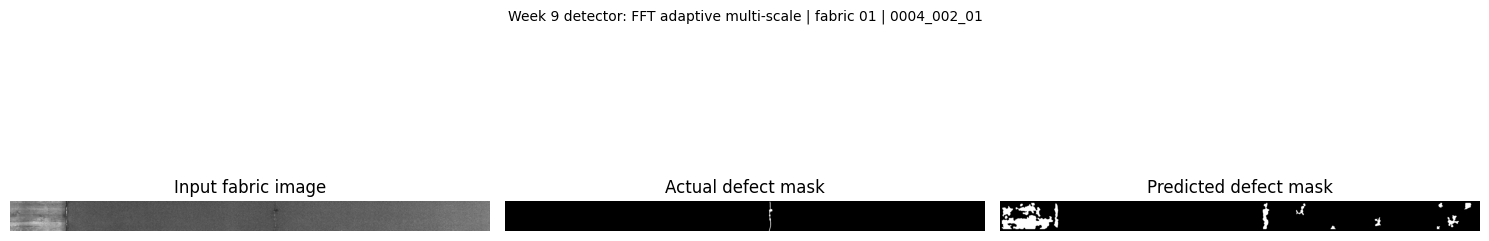

Detection flagged       : True
Detected regions        : 14
Confidence              : 1.000
Pixel IoU (covered area): 0.024
Pixel precision         : 0.025
Pixel recall            : 0.940


In [27]:
DATASET_DIR = Path("/content/drive/MyDrive/ECE501/archive")
DEFECT_IMAGE_DIR = DATASET_DIR / "Defect_images"
MASK_IMAGE_DIR = DATASET_DIR / "Mask_images"

# Select a held-out TEST source image for which the raw image and mask files exist.
demo_candidates = (
    defect_df[defect_df.split == "test"][["source", "fabric"]]
    .drop_duplicates()
    .to_dict("records")
)
demo_path, demo_fabric, demo_source = None, None, None
for item in demo_candidates:
    candidate = DEFECT_IMAGE_DIR / f"{item['source']}.png"
    mask_files = list(MASK_IMAGE_DIR.glob(f"{item['source']}_mask*.png"))
    if candidate.exists() and mask_files:
        demo_path, demo_fabric, demo_source = candidate, item["fabric"], item["source"]
        break

if demo_path is None:
    print("No held-out TEST raw image with matching mask files was found.")
    print("Check the AITEX archive paths and filenames before running this demo.")
else:
    demo_result = week9_detector.inspect_image(demo_path, demo_fabric)

    actual_mask = np.zeros(demo_result["input_image"].shape, dtype=bool)
    for mask_path in sorted(MASK_IMAGE_DIR.glob(f"{demo_source}_mask*.png")):
        mask_img = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if mask_img is not None:
            if mask_img.shape != actual_mask.shape:
                raise ValueError(
                    f"Mask size {mask_img.shape} does not match image size {actual_mask.shape}: {mask_path.name}"
                )
            actual_mask |= mask_img > 0

    predicted_mask = demo_result["mask"]
    scored = demo_result["covered"]
    gt_scored = actual_mask & scored
    pred_scored = predicted_mask & scored
    tp = int((pred_scored & gt_scored).sum())
    fp = int((pred_scored & ~gt_scored).sum())
    fn = int((~pred_scored & gt_scored).sum())
    demo_iou = tp / (tp + fp + fn + 1e-9)
    demo_precision = tp / (tp + fp + 1e-9)
    demo_recall = tp / (tp + fn + 1e-9)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].imshow(demo_result["input_image"], cmap="gray")
    axes[0].set_title("Input fabric image")
    axes[1].imshow(actual_mask, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Actual defect mask")
    axes[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title("Predicted defect mask")
    for ax in axes:
        ax.axis("off")
    plt.suptitle(
        f"Week 9 detector: {selected_week9_method} | fabric {demo_fabric} | {demo_source}",
        fontsize=10
    )
    plt.tight_layout()
    plt.show()

    print(f"Detection flagged       : {demo_result['flagged']}")
    print(f"Detected regions        : {len(demo_result['regions'])}")
    print(f"Confidence              : {demo_result['confidence']:.3f}")
    print(f"Pixel IoU (covered area): {demo_iou:.3f}")
    print(f"Pixel precision         : {demo_precision:.3f}")
    print(f"Pixel recall            : {demo_recall:.3f}")


## FINAL INTEGRATION 3 — WEEK 9 METHOD RESULTS

This compact table compares the methods evaluated in Week 9. It uses TEST estimates when the final TEST evaluation has been run; otherwise, it uses DEV estimates and labels them clearly. The best-performing method is selected by **Pooled pixel F1**, the main pixel-level localization metric, and highlighted in the table.

In [28]:
final_results_split = "TEST" if RUN_FINAL_TEST and test_point is not None else "DEV"
final_results_source = test_point if final_results_split == "TEST" else dev_point

final_results_table = pd.DataFrame([
    {
        "Method": method,
        "Pooled pixel F1": final_results_source[method]["Pooled pixel F1"],
        "Defect detection rate": final_results_source[method]["Defect detection rate"],
        "Image recall": final_results_source[method]["Image recall"],
        "False-alarm rate": final_results_source[method]["False-alarm rate"],
        "Image AUROC": final_results_source[method]["Image AUROC"]
    }
    for method in METHODS
]).sort_values("Pooled pixel F1", ascending=False).reset_index(drop=True)

best_method_row = final_results_table.iloc[0]["Method"]
print(f"Week 9 method comparison — {final_results_split} split")
print(f"Best-performing method by pooled pixel F1: {best_method_row}")

display(
    final_results_table.style
    .format({
        "Pooled pixel F1": "{:.3f}",
        "Defect detection rate": "{:.3f}",
        "Image recall": "{:.3f}",
        "False-alarm rate": "{:.3f}",
        "Image AUROC": "{:.3f}"
    })
    .highlight_max(subset=["Pooled pixel F1"], color="#d9ead3")
)

print("\nThe reusable detector above uses the same best-performing method selected from this comparison.")


Week 9 method comparison — DEV split
Best-performing method by pooled pixel F1: FFT adaptive multi-scale


,Method,Pooled pixel F1,Defect detection rate,Image recall,False-alarm rate,Image AUROC
0,FFT adaptive multi-scale,0.141,0.454,0.467,0.011,0.830
1,FFT fixed multi-scale (per-fabric),0.089,0.429,0.454,0.029,0.829
2,FFT adaptive multi-scale (tuned),0.074,0.497,0.559,0.071,0.900
3,Gabor,0.033,0.123,0.204,0.096,0.786
4,FFT fixed multi-scale,0.025,0.233,0.257,0.018,0.822
5,FFT fixed single-scale,0.021,0.147,0.191,0.004,0.779
6,GLCM,0.019,0.067,0.105,0.107,0.656
7,LBP self-reference,0.012,0.061,0.099,0.100,0.822
8,LBP,0.000,0.000,0.053,0.107,0.643



The reusable detector above uses the same best-performing method selected from this comparison.
